In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

folders = [
    "raw/real/inaturalist",
    "raw/real/caltech",
    "raw/fake/sdxl",
    "processed/real",
    "processed/fake",
    "final/train/real",
    "final/train/fake",
    "final/validation/real",
    "final/validation/fake",
    "final/test/real",
    "final/test/fake",
    "metadata",
    "reports",
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Folders created successfully.")

Folders created successfully.


In [ ]:
!wget -q --show-progress \
https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_annotations.tar.gz \
-O /content/cct_metadata.tar.gz

/content/cct_metada 100%[===================>]   2.86M  2.59MB/s    in 1.1s    


In [ ]:
!mkdir -p /content/cct_metadata
!tar -xzf /content/cct_metadata.tar.gz -C /content/cct_metadata

In [ ]:
!find /content/cct_metadata -type f


/content/cct_metadata/eccv_18_annotation_files/cis_test_annotations.json
/content/cct_metadata/eccv_18_annotation_files/train_annotations.json
/content/cct_metadata/eccv_18_annotation_files/trans_val_annotations.json
/content/cct_metadata/eccv_18_annotation_files/trans_test_annotations.json
/content/cct_metadata/eccv_18_annotation_files/cis_val_annotations.json


In [ ]:
!pip install -q pandas


In [ ]:
import json
import pandas as pd
from pathlib import Path

meta_root = Path("/content/cct_metadata")

json_files = list(meta_root.rglob("*.json"))

print("JSON files found:")
for f in json_files:
    print(f)

JSON files found:
/content/cct_metadata/eccv_18_annotation_files/cis_test_annotations.json
/content/cct_metadata/eccv_18_annotation_files/train_annotations.json
/content/cct_metadata/eccv_18_annotation_files/trans_val_annotations.json
/content/cct_metadata/eccv_18_annotation_files/trans_test_annotations.json
/content/cct_metadata/eccv_18_annotation_files/cis_val_annotations.json


In [ ]:
all_rows = []

for json_file in json_files:
    try:
        with open(json_file, "r") as f:
            data = json.load(f)

        if not all(k in data for k in ["images", "annotations", "categories"]):
            continue

        category_lookup = {
            str(c["id"]): c["name"]
            for c in data["categories"]
        }

        image_lookup = {
            str(i["id"]): i
            for i in data["images"]
        }

        for ann in data["annotations"]:

            image_id = str(ann["image_id"])
            category_id = str(ann["category_id"])

            image = image_lookup.get(image_id)

            if image is None:
                continue

            species = category_lookup.get(category_id, "unknown")

            if species.lower() == "empty":
                continue

            all_rows.append({
                "image_id": image_id,
                "file_name": image.get("file_name"),
                "species": species,
                "location": image.get("location"),
                "sequence_id": image.get("seq_id"),
                "width": image.get("width"),
                "height": image.get("height"),
                "metadata_file": json_file.name
            })

    except Exception as e:
        print("Skipped", json_file, e)

caltech_df = pd.DataFrame(all_rows)

caltech_df = caltech_df.drop_duplicates(
    subset=["image_id"]
)

print("Non-empty images:", len(caltech_df))

Non-empty images: 53850


In [ ]:
species_stats = (
    caltech_df
    .groupby("species")
    .agg(
        images=("image_id", "count"),
        locations=("location", "nunique")
    )
    .sort_values("images", ascending=False)
)

print(species_stats)

          images  locations
species                    
opossum    13688         17
raccoon     7841         19
rabbit      5549         19
coyote      5314         18
bobcat      4961         19
cat         4601         13
squirrel    3181         17
dog         2788         16
car         2613          2
bird        1402         18
skunk        857         16
rodent       812         10
deer         207          2
badger        28          7
fox            8          2


In [ ]:
SELECTED_SPECIES = [
    "opossum",
    "raccoon",
    "rabbit",
    "coyote",
    "bobcat",
    "squirrel",
    "skunk"
]

print(SELECTED_SPECIES)

['opossum', 'raccoon', 'rabbit', 'coyote', 'bobcat', 'squirrel', 'skunk']


In [ ]:
species_quality = (
    caltech_df[
        caltech_df["species"].isin(SELECTED_SPECIES)
    ]
    .groupby("species")
    .agg(
        images=("image_id", "count"),
        locations=("location", "nunique"),
        sequences=("sequence_id", "nunique")
    )
    .sort_values("images", ascending=False)
)

print(species_quality)


          images  locations  sequences
species                               
opossum    13688         17       4494
raccoon     7841         19       2619
rabbit      5549         19       1865
coyote      5314         18       2604
bobcat      4961         19       1890
squirrel    3181         17       1076
skunk        857         16        402


In [ ]:
selected_pool = (
    caltech_df[
        caltech_df["species"].isin(SELECTED_SPECIES)
    ]
    .dropna(subset=["sequence_id"])
    .groupby(
        ["species", "sequence_id"],
        group_keys=False
    )
    .sample(
        n=1,
        random_state=401
    )
)

print("Images after one-per-sequence filtering:")
print(selected_pool["species"].value_counts())

Images after one-per-sequence filtering:
species
opossum     4494
raccoon     2619
coyote      2604
bobcat      1890
rabbit      1865
squirrel    1076
skunk        402
Name: count, dtype: int64


In [ ]:
print(
    selected_pool.groupby("species")["location"]
    .nunique()
)

species
bobcat      19
coyote      18
opossum     17
rabbit      19
raccoon     19
skunk       16
squirrel    17
Name: location, dtype: int64


In [ ]:
location_distribution = (
    selected_pool
    .groupby(["species", "location"])
    .size()
    .reset_index(name="images")
)

print(location_distribution.to_string(index=False))

 species  location  images
  bobcat         0     129
  bobcat         7      25
  bobcat        28     122
  bobcat        33      10
  bobcat        38       4
  bobcat        40       1
  bobcat        43     369
  bobcat        46     333
  bobcat        51      90
  bobcat        61      20
  bobcat        78      37
  bobcat        90       5
  bobcat       100      19
  bobcat       105      43
  bobcat       108      11
  bobcat       115      33
  bobcat       120     218
  bobcat       125     265
  bobcat       130     156
  coyote         0     321
  coyote         7     208
  coyote        28      14
  coyote        38      16
  coyote        40       6
  coyote        43     278
  coyote        46     292
  coyote        51      49
  coyote        61      61
  coyote        78      35
  coyote        88     120
  coyote        90      23
  coyote       100       4
  coyote       108       9
  coyote       115     143
  coyote       120     923
  coyote       125      17
 

In [ ]:
import pandas as pd

CANDIDATES_PER_SPECIES = 170

caltech_candidates = []

for species in SELECTED_SPECIES:

    pool = selected_pool[
        selected_pool["species"] == species
    ].copy()

    print(
        species,
        "available unique sequences:",
        len(pool),
        "locations:",
        pool["location"].nunique()
    )

    if len(pool) < CANDIDATES_PER_SPECIES:
        print(
            "WARNING:",
            species,
            "has fewer than",
            CANDIDATES_PER_SPECIES,
            "unique sequences"
        )

    n = min(
        CANDIDATES_PER_SPECIES,
        len(pool)
    )

    sample = pool.sample(
        n=n,
        random_state=401
    )

    caltech_candidates.append(sample)

caltech_candidates = pd.concat(
    caltech_candidates,
    ignore_index=True
)

print("\nFinal candidate counts:")
print(
    caltech_candidates["species"]
    .value_counts()
)

print(
    "\nTotal candidates:",
    len(caltech_candidates)
)

opossum available unique sequences: 4494 locations: 17
raccoon available unique sequences: 2619 locations: 19
rabbit available unique sequences: 1865 locations: 19
coyote available unique sequences: 2604 locations: 18
bobcat available unique sequences: 1890 locations: 19
squirrel available unique sequences: 1076 locations: 17
skunk available unique sequences: 402 locations: 16

Final candidate counts:
species
opossum     170
raccoon     170
rabbit      170
coyote      170
bobcat      170
squirrel    170
skunk       170
Name: count, dtype: int64

Total candidates: 1190


In [ ]:
candidate_file = (
    ROOT /
    "metadata/caltech_candidate_selection.csv"
)

caltech_candidates.to_csv(
    candidate_file,
    index=False
)

print("Saved to:")
print(candidate_file)

Saved to:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/caltech_candidate_selection.csv


In [ ]:
from pathlib import Path

image_root = Path("/content/cct_images")

files = list(image_root.rglob("*.jpg"))

print("JPG images found:", len(files))

JPG images found: 0


In [ ]:
!find /content/cct_images -type f | head -30

find: ‘/content/cct_images’: No such file or directory


In [ ]:
!which gsutil

/tools/google-cloud-sdk/bin/gsutil


In [ ]:
test_row = caltech_candidates.iloc[0]

print("Species:", test_row["species"])
print("File name:", test_row["file_name"])
print("Image ID:", test_row["image_id"])
print("Location:", test_row["location"])
print("Sequence:", test_row["sequence_id"])

Species: opossum
File name: 59bfdf49-23d2-11e8-a6a3-ec086b02610b.jpg
Image ID: 59bfdf49-23d2-11e8-a6a3-ec086b02610b
Location: 33
Sequence: 6f0808de-5567-11e8-bb1d-dca9047ef277


In [ ]:
from pathlib import Path

file_name = str(test_row["file_name"])

# Avoid duplicated cct_images/ if metadata already contains it
file_name_clean = file_name.replace("cct_images/", "")

gcs_path = (
    "gs://public-datasets-lila/"
    "caltech-unzipped/cct_images/"
    + file_name_clean
)

print(gcs_path)

gs://public-datasets-lila/caltech-unzipped/cct_images/59bfdf49-23d2-11e8-a6a3-ec086b02610b.jpg


In [ ]:
import subprocess

result = subprocess.run(
    ["gsutil", "ls", gcs_path],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("OUTPUT:")
print(result.stdout)

print("ERROR:")
print(result.stderr)

Return code: 0
OUTPUT:
gs://public-datasets-lila/caltech-unzipped/cct_images/59bfdf49-23d2-11e8-a6a3-ec086b02610b.jpg

ERROR:



In [ ]:
from pathlib import Path

test_dir = Path("/content/test_caltech")
test_dir.mkdir(exist_ok=True)

In [ ]:
result = subprocess.run(
    ["gsutil", "cp", gcs_path, str(test_dir)],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0

Copying gs://public-datasets-lila/caltech-unzipped/cct_images/59bfdf49-23d2-11e8-a6a3-ec086b02610b.jpg...
/ [0 files][    0.0 B/346.2 KiB]                                                
-
- [1 files][346.2 KiB/346.2 KiB]                                                
Operation completed over 1 objects/346.2 KiB.                                    



In [ ]:
list(test_dir.iterdir())

[PosixPath('/content/test_caltech/59bfdf49-23d2-11e8-a6a3-ec086b02610b.jpg')]

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

test_images = [
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

img = Image.open(test_images[0])

print("Size:", img.size)
print("Mode:", img.mode)

plt.figure(figsize=(7,7))
plt.imshow(img)
plt.axis("off")
plt.show()

Size: (2048, 1494)
Mode: RGB


In [ ]:
import pandas as pd

TARGET_PER_SPECIES = 170
MAX_PER_LOCATION = 20

balanced_candidates = []

for species in SELECTED_SPECIES:

    pool = selected_pool[
        selected_pool["species"] == species
    ].copy()

    selected_parts = []

    # First take a maximum of 20 unique-sequence images
    # from each camera location.
    for location, group in pool.groupby("location"):

        n = min(
            MAX_PER_LOCATION,
            len(group)
        )

        sampled = group.sample(
            n=n,
            random_state=401
        )

        selected_parts.append(sampled)

    temp = pd.concat(
        selected_parts,
        ignore_index=True
    )

    # If more than 170 were selected,
    # reduce to exactly 170.
    if len(temp) > TARGET_PER_SPECIES:

        temp = temp.sample(
            n=TARGET_PER_SPECIES,
            random_state=401
        )

    # If fewer than 170,
    # add unused unique-sequence images.
    elif len(temp) < TARGET_PER_SPECIES:

        already_used = set(
            temp["image_id"]
        )

        remaining = pool[
            ~pool["image_id"].isin(already_used)
        ]

        needed = (
            TARGET_PER_SPECIES
            - len(temp)
        )

        if len(remaining) >= needed:

            extra = remaining.sample(
                n=needed,
                random_state=402
            )

            temp = pd.concat(
                [temp, extra],
                ignore_index=True
            )

    balanced_candidates.append(temp)

caltech_candidates = pd.concat(
    balanced_candidates,
    ignore_index=True
)

print("\nImages selected per species:")
print(caltech_candidates["species"].value_counts())

print("\nCamera locations represented:")
print(
    caltech_candidates
    .groupby("species")["location"]
    .nunique()
)


Images selected per species:
species
opossum     170
raccoon     170
rabbit      170
coyote      170
bobcat      170
squirrel    170
skunk       170
Name: count, dtype: int64

Camera locations represented:
species
bobcat      18
coyote      18
opossum     17
rabbit      19
raccoon     18
skunk       16
squirrel    17
Name: location, dtype: int64


In [ ]:
distribution = (
    caltech_candidates
    .groupby(["species", "location"])
    .size()
    .reset_index(name="selected_images")
)

print(distribution.to_string(index=False))

 species  location  selected_images
  bobcat         0               15
  bobcat         7               10
  bobcat        28               13
  bobcat        33                7
  bobcat        38                1
  bobcat        43                9
  bobcat        46               12
  bobcat        51                9
  bobcat        61               15
  bobcat        78               10
  bobcat        90                5
  bobcat       100                8
  bobcat       105                7
  bobcat       108                7
  bobcat       115               11
  bobcat       120                8
  bobcat       125               11
  bobcat       130               12
  coyote         0               14
  coyote         7               11
  coyote        28               10
  coyote        38               11
  coyote        40                2
  coyote        43               10
  coyote        46               11
  coyote        51               10
  coyote        61          

In [ ]:
caltech_candidates.to_csv(
    ROOT / "metadata/caltech_candidate_selection.csv",
    index=False
)

print("Saved:", len(caltech_candidates))

Saved: 1190


In [ ]:
import subprocess
import pandas as pd
from pathlib import Path

OUTPUT = ROOT / "raw/real/caltech"

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

download_records = []

total = len(caltech_candidates)

for counter, (_, row) in enumerate(
    caltech_candidates.iterrows(),
    start=1
):

    species = str(row["species"])

    image_id = str(row["image_id"])

    original_file = str(
        row["file_name"]
    )

    clean_file = original_file.replace(
        "cct_images/",
        ""
    )

    cloud_path = (
        "gs://public-datasets-lila/"
        "caltech-unzipped/cct_images/"
        + clean_file
    )

    extension = Path(clean_file).suffix

    safe_species = species.replace(
        " ",
        "_"
    )

    destination = (
        OUTPUT /
        f"cct_{safe_species}_{image_id}{extension}"
    )

    # Allows you to restart the notebook
    # without downloading existing images again.
    if destination.exists():

        success = True
        status = "already_downloaded"

    else:

        result = subprocess.run(
            [
                "gsutil",
                "-q",
                "cp",
                cloud_path,
                str(destination)
            ],
            capture_output=True,
            text=True
        )

        success = (
            result.returncode == 0
        )

        status = (
            "downloaded"
            if success
            else "failed"
        )

    download_records.append({
        "image_id": image_id,
        "filename": destination.name,
        "label": "real",
        "source": "caltech",
        "species": species,
        "location": row["location"],
        "sequence_id": row["sequence_id"],
        "group_id": (
            "cct_location_"
            + str(row["location"])
        ),
        "original_file": original_file,
        "cloud_path": cloud_path,
        "local_path": str(destination),
        "download_success": success,
        "download_status": status
    })

    print(
        f"{counter}/{total}",
        species,
        status
    )

# Save the log.
download_df = pd.DataFrame(
    download_records
)

download_df.to_csv(
    ROOT /
    "metadata/caltech_download_log.csv",
    index=False
)

print("\nFINISHED")

1/1190 opossum downloaded
2/1190 opossum downloaded
3/1190 opossum downloaded
4/1190 opossum downloaded
5/1190 opossum downloaded
6/1190 opossum downloaded
7/1190 opossum downloaded
8/1190 opossum downloaded
9/1190 opossum downloaded
10/1190 opossum downloaded
11/1190 opossum downloaded
12/1190 opossum downloaded
13/1190 opossum downloaded
14/1190 opossum downloaded
15/1190 opossum downloaded
16/1190 opossum downloaded
17/1190 opossum downloaded
18/1190 opossum downloaded
19/1190 opossum downloaded
20/1190 opossum downloaded
21/1190 opossum downloaded
22/1190 opossum downloaded
23/1190 opossum downloaded
24/1190 opossum downloaded
25/1190 opossum downloaded
26/1190 opossum downloaded
27/1190 opossum downloaded
28/1190 opossum downloaded
29/1190 opossum downloaded
30/1190 opossum downloaded
31/1190 opossum downloaded
32/1190 opossum downloaded
33/1190 opossum downloaded
34/1190 opossum downloaded
35/1190 opossum downloaded
36/1190 opossum downloaded
37/1190 opossum downloaded
38/1190 op

In [ ]:
print(
    download_df["download_success"]
    .value_counts()
)

download_success
True    1190
Name: count, dtype: int64


In [ ]:
downloaded_files = [
    p
    for p in (
        ROOT / "raw/real/caltech"
    ).rglob("*")
    if p.suffix.lower()
    in [".jpg", ".jpeg", ".png"]
]

print(
    "Actual image files:",
    len(downloaded_files)
)

Actual image files: 1190


In [ ]:
print(
    download_df[
        download_df["download_success"]
    ]["species"]
    .value_counts()
)

species
opossum     170
raccoon     170
rabbit      170
coyote      170
bobcat      170
squirrel    170
skunk       170
Name: count, dtype: int64


In [ ]:
from pathlib import Path
import pandas as pd

CALTECH_DIR = ROOT / "raw/real/caltech"

def make_local_path(row):
    original_file = str(row["file_name"])
    extension = Path(original_file).suffix

    safe_species = str(row["species"]).replace(" ", "_")

    return str(
        CALTECH_DIR /
        f"cct_{safe_species}_{row['image_id']}{extension}"
    )

caltech_qc = caltech_candidates.copy()

caltech_qc["label"] = "real"
caltech_qc["source"] = "caltech_camera_traps"
caltech_qc["local_path"] = caltech_qc.apply(
    make_local_path,
    axis=1
)

print(caltech_qc.head())

print("\nRows:", len(caltech_qc))

                               image_id  \
0  58c7ef80-23d2-11e8-a6a3-ec086b02610b   
1  5976a4fe-23d2-11e8-a6a3-ec086b02610b   
2  59ccd2bd-23d2-11e8-a6a3-ec086b02610b   
3  58bd1bff-23d2-11e8-a6a3-ec086b02610b   
4  5a2c8638-23d2-11e8-a6a3-ec086b02610b   

                                  file_name  species  location  \
0  58c7ef80-23d2-11e8-a6a3-ec086b02610b.jpg  opossum       130   
1  5976a4fe-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        40   
2  59ccd2bd-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        28   
3  58bd1bff-23d2-11e8-a6a3-ec086b02610b.jpg  opossum       105   
4  5a2c8638-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        33   

                            sequence_id  width  height  \
0  6f0cfe1e-5567-11e8-8ccf-dca9047ef277   2048    1494   
1  6f05b80c-5567-11e8-b394-dca9047ef277   2048    1494   
2  6f12b4d1-5567-11e8-bfdd-dca9047ef277   2048    1494   
3  6f19d18f-5567-11e8-a875-dca9047ef277   2048    1494   
4  6f08adc0-5567-11e8-a23f-dca9047ef277   2048    1494

In [ ]:
caltech_qc["file_exists"] = caltech_qc["local_path"].apply(
    lambda x: Path(x).exists()
)

print(caltech_qc["file_exists"].value_counts())

file_exists
True    1190
Name: count, dtype: int64


In [ ]:
from PIL import Image

def inspect_image(path):

    try:
        with Image.open(path) as img:

            img.load()

            width, height = img.size
            mode = img.mode

            if width < 256 or height < 256:
                return {
                    "readable": True,
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "technical_status": "too_small"
                }

            return {
                "readable": True,
                "width": width,
                "height": height,
                "mode": mode,
                "technical_status": "ok"
            }

    except Exception as e:

        return {
            "readable": False,
            "width": None,
            "height": None,
            "mode": None,
            "technical_status": "corrupt"
        }

In [ ]:
inspection_results = (
    caltech_qc["local_path"]
    .apply(inspect_image)
    .apply(pd.Series)
)

caltech_qc = pd.concat(
    [
        caltech_qc.reset_index(drop=True),
        inspection_results.reset_index(drop=True)
    ],
    axis=1
)

print(caltech_qc["technical_status"].value_counts())

technical_status
ok    1190
Name: count, dtype: int64


In [ ]:
print(
    caltech_qc[
        ["width", "height"]
    ].describe()
)

             width        width       height       height
count  1190.000000  1190.000000  1190.000000  1190.000000
mean   2066.500840  2066.500840  1511.369748  1511.369748
std      95.591987    95.591987    79.650304    79.650304
min    2048.000000  2048.000000  1494.000000  1494.000000
25%    2048.000000  2048.000000  1494.000000  1494.000000
50%    2048.000000  2048.000000  1494.000000  1494.000000
75%    2048.000000  2048.000000  1494.000000  1494.000000
max    2560.000000  2560.000000  1920.000000  1920.000000


In [ ]:
resolution_counts = (
    caltech_qc
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print(resolution_counts.head(20))

ValueError: Grouper for 'width' not 1-dimensional

In [ ]:
from pathlib import Path
import pandas as pd

CALTECH_DIR = ROOT / "raw/real/caltech"

# Start again from the clean candidate table
caltech_qc = caltech_candidates.copy()

# Rename dimensions that came from Caltech metadata
caltech_qc = caltech_qc.rename(columns={
    "width": "metadata_width",
    "height": "metadata_height"
})

def make_local_path(row):
    original_file = str(row["file_name"])
    extension = Path(original_file).suffix

    safe_species = str(row["species"]).replace(" ", "_")

    return str(
        CALTECH_DIR /
        f"cct_{safe_species}_{row['image_id']}{extension}"
    )

caltech_qc["label"] = "real"
caltech_qc["source"] = "caltech_camera_traps"

caltech_qc["local_path"] = caltech_qc.apply(
    make_local_path,
    axis=1
)

caltech_qc["file_exists"] = (
    caltech_qc["local_path"]
    .apply(lambda x: Path(x).exists())
)

print("Rows:", len(caltech_qc))
print("\nFiles exist:")
print(caltech_qc["file_exists"].value_counts())

Rows: 1190

Files exist:
file_exists
True    1190
Name: count, dtype: int64


In [ ]:
from PIL import Image

def inspect_image(path):

    try:
        with Image.open(path) as img:

            img.load()

            actual_width, actual_height = img.size
            image_mode = img.mode

            if actual_width < 256 or actual_height < 256:
                return {
                    "readable": True,
                    "actual_width": actual_width,
                    "actual_height": actual_height,
                    "image_mode": image_mode,
                    "technical_status": "too_small"
                }

            return {
                "readable": True,
                "actual_width": actual_width,
                "actual_height": actual_height,
                "image_mode": image_mode,
                "technical_status": "ok"
            }

    except Exception as e:

        return {
            "readable": False,
            "actual_width": None,
            "actual_height": None,
            "image_mode": None,
            "technical_status": "corrupt"
        }

In [ ]:
inspection_results = (
    caltech_qc["local_path"]
    .apply(inspect_image)
    .apply(pd.Series)
)

caltech_qc = pd.concat(
    [
        caltech_qc.reset_index(drop=True),
        inspection_results.reset_index(drop=True)
    ],
    axis=1
)

print(caltech_qc["technical_status"].value_counts())

technical_status
ok    1190
Name: count, dtype: int64


In [ ]:
duplicate_columns = caltech_qc.columns[
    caltech_qc.columns.duplicated()
]

print("Duplicate column names:")
print(list(duplicate_columns))

Duplicate column names:
[]


In [ ]:
print(
    caltech_qc[
        ["actual_width", "actual_height"]
    ].describe()
)

       actual_width  actual_height
count   1190.000000    1190.000000
mean    2066.500840    1511.369748
std       95.591987      79.650304
min     2048.000000    1494.000000
25%     2048.000000    1494.000000
50%     2048.000000    1494.000000
75%     2048.000000    1494.000000
max     2560.000000    1920.000000


In [ ]:
resolution_counts = (
    caltech_qc
    .groupby(
        ["actual_width", "actual_height"]
    )
    .size()
    .sort_values(ascending=False)
)

print(resolution_counts.head(20))

actual_width  actual_height
2048          1494             1091
              1536               56
2560          1920               43
dtype: int64


In [ ]:
print(
    caltech_qc[
        [
            "metadata_width",
            "metadata_height",
            "actual_width",
            "actual_height"
        ]
    ].head(10)
)

   metadata_width  metadata_height  actual_width  actual_height
0            2048             1494          2048           1494
1            2048             1494          2048           1494
2            2048             1494          2048           1494
3            2048             1494          2048           1494
4            2048             1494          2048           1494
5            2048             1494          2048           1494
6            2048             1494          2048           1494
7            2048             1494          2048           1494
8            2048             1494          2048           1494
9            2048             1494          2048           1494


In [ ]:
caltech_qc.to_csv(
    ROOT / "metadata/caltech_qc_full.csv",
    index=False
)

print("Saved:", len(caltech_qc), "rows")

Saved: 1190 rows


In [ ]:
print(caltech_qc["technical_status"].value_counts())

technical_status
ok    1190
Name: count, dtype: int64


In [ ]:
import numpy as np
from PIL import Image

def calculate_brightness(path):

    try:
        with Image.open(path) as img:

            gray = img.convert("L")

            # Smaller temporary copy for faster calculation
            gray.thumbnail((256, 256))

            arr = np.asarray(
                gray,
                dtype=np.float32
            )

            return float(arr.mean())

    except Exception:
        return None

In [ ]:
caltech_qc["mean_brightness"] = (
    caltech_qc["local_path"]
    .apply(calculate_brightness)
)

print(
    caltech_qc["mean_brightness"]
    .describe()
)

count    1190.000000
mean       77.897803
std        39.219092
min        12.706759
25%        47.340341
50%        63.167927
75%       119.242661
max       158.569519
Name: mean_brightness, dtype: float64


In [ ]:
brightness_threshold = (
    caltech_qc["mean_brightness"]
    .quantile(0.05)
)

print(
    "Darkest 5% threshold:",
    brightness_threshold
)

caltech_qc["dark_review"] = (
    caltech_qc["mean_brightness"]
    <= brightness_threshold
)

print(
    caltech_qc["dark_review"]
    .value_counts()
)

Darkest 5% threshold: 29.31425361633301
dark_review
False    1130
True       60
Name: count, dtype: int64


In [ ]:
brightness_by_species = (
    caltech_qc
    .groupby("species")["mean_brightness"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .round(2)
)

print(brightness_by_species)

          count    mean  median    min     max
species                                       
bobcat      170   75.63   62.61  28.52  158.57
coyote      170   80.47   63.46  13.82  151.02
opossum     170   54.66   54.41  21.48  145.16
rabbit      170  108.91  127.15  26.01  155.86
raccoon     170   51.06   50.15  12.71   90.90
skunk       170   51.04   50.28  25.67  104.34
squirrel    170  123.51  124.13  46.68  155.22


In [ ]:
brightness_by_species.to_csv(
    ROOT /
    "reports/caltech_brightness_by_category.csv"
)

In [ ]:
import hashlib

def sha256_file(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()

In [ ]:
caltech_qc["sha256"] = (
    caltech_qc["local_path"]
    .apply(sha256_file)
)

exact_duplicates = caltech_qc[
    caltech_qc.duplicated(
        subset=["sha256"],
        keep=False
    )
].sort_values("sha256")

print(
    "Images involved in exact duplicates:",
    len(exact_duplicates)
)

Images involved in exact duplicates: 0


In [ ]:
exact_duplicates.to_csv(
    ROOT /
    "metadata/caltech_exact_duplicates.csv",
    index=False
)

In [ ]:
!pip install -q imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 2.1 MB/s eta 0:00:00


In [ ]:
import imagehash

def calculate_phash(path):

    try:
        with Image.open(path) as img:

            return str(
                imagehash.phash(
                    img.convert("RGB")
                )
            )

    except Exception:
        return None

In [ ]:
caltech_qc["phash"] = (
    caltech_qc["local_path"]
    .apply(calculate_phash)
)

print(
    caltech_qc[
        [
            "species",
            "image_id",
            "phash"
        ]
    ].head()
)

   species                              image_id             phash
0  opossum  58c7ef80-23d2-11e8-a6a3-ec086b02610b  c76f3118613ece68
1  opossum  5976a4fe-23d2-11e8-a6a3-ec086b02610b  c21b6c3b64f90ce5
2  opossum  59ccd2bd-23d2-11e8-a6a3-ec086b02610b  c23f2cd873e163e0
3  opossum  58bd1bff-23d2-11e8-a6a3-ec086b02610b  cad436f1636566c8
4  opossum  5a2c8638-23d2-11e8-a6a3-ec086b02610b  cf082f9630fc6ae8


In [ ]:
from itertools import combinations

near_duplicate_pairs = []

for species in SELECTED_SPECIES:

    subset = caltech_qc[
        caltech_qc["species"] == species
    ]

    records = subset.to_dict("records")

    for a, b in combinations(records, 2):

        if pd.isna(a["phash"]) or pd.isna(b["phash"]):
            continue

        hash_a = imagehash.hex_to_hash(
            a["phash"]
        )

        hash_b = imagehash.hex_to_hash(
            b["phash"]
        )

        distance = hash_a - hash_b

        if distance <= 4:

            near_duplicate_pairs.append({
                "species": species,
                "image_1": a["image_id"],
                "image_2": b["image_id"],
                "path_1": a["local_path"],
                "path_2": b["local_path"],
                "phash_distance": distance
            })

near_duplicates_df = pd.DataFrame(
    near_duplicate_pairs
)

print(
    "Potential near-duplicate pairs:",
    len(near_duplicates_df)
)

Potential near-duplicate pairs: 265


In [ ]:
near_duplicates_df.to_csv(
    ROOT /
    "metadata/caltech_near_duplicate_review.csv",
    index=False
)

In [ ]:
caltech_qc.to_csv(
    ROOT /
    "metadata/caltech_qc_full.csv",
    index=False
)

print(
    "QC metadata saved:",
    len(caltech_qc)
)

QC metadata saved: 1190


In [ ]:
dark_images = (
    caltech_qc[
        caltech_qc["dark_review"] == True
    ]
    .sort_values("mean_brightness")
    .reset_index(drop=True)
)

print(
    "Images requiring darkness review:",
    len(dark_images)
)

Images requiring darkness review: 60


In [ ]:
import matplotlib.pyplot as plt
import math

DARK_DIR = (
    ROOT /
    "reports/caltech_dark_review"
)

DARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGES_PER_SHEET = 25

number_of_sheets = math.ceil(
    len(dark_images) /
    IMAGES_PER_SHEET
)

for sheet_number in range(number_of_sheets):

    start = (
        sheet_number *
        IMAGES_PER_SHEET
    )

    end = min(
        start + IMAGES_PER_SHEET,
        len(dark_images)
    )

    page = dark_images.iloc[start:end]

    fig, axes = plt.subplots(
        5,
        5,
        figsize=(15, 15)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes,
        page.iterrows()
    ):

        img = Image.open(
            row["local_path"]
        )

        ax.imshow(img)

        ax.set_title(
            f"{row['species']}\n"
            f"{str(row['image_id'])[:8]}\n"
            f"B={row['mean_brightness']:.1f}",
            fontsize=7
        )

        ax.axis("off")

    plt.suptitle(
        f"Dark-image review — "
        f"Sheet {sheet_number + 1}",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        DARK_DIR /
        f"dark_review_{sheet_number + 1}.jpg",
        dpi=120
    )

    plt.close()

print("Dark review sheets created.")

Dark review sheets created.


In [ ]:
manual_qc = caltech_qc[
    [
        "image_id",
        "species",
        "location",
        "sequence_id",
        "local_path",
        "actual_width",
        "actual_height",
        "mean_brightness",
        "dark_review",
        "sha256",
        "phash"
    ]
].copy()

manual_qc["manual_decision"] = ""
manual_qc["rejection_reason"] = ""
manual_qc["notes"] = ""

manual_qc.to_csv(
    ROOT /
    "metadata/caltech_manual_qc.csv",
    index=False
)

print(
    "Manual QC rows:",
    len(manual_qc)
)

Manual QC rows: 1190


In [ ]:
exact_duplicates = caltech_qc[
    caltech_qc.duplicated(
        subset=["sha256"],
        keep=False
    )
].sort_values("sha256")

print(
    "Images involved in exact duplicates:",
    len(exact_duplicates)
)

Images involved in exact duplicates: 0


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import math

PAIR_DIR = (
    ROOT /
    "reports/caltech_near_duplicate_pairs"
)

PAIR_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PAIRS_PER_SHEET = 10

number_of_sheets = math.ceil(
    len(near_duplicates_df) /
    PAIRS_PER_SHEET
)

for sheet_no in range(number_of_sheets):

    start = sheet_no * PAIRS_PER_SHEET

    end = min(
        start + PAIRS_PER_SHEET,
        len(near_duplicates_df)
    )

    page = near_duplicates_df.iloc[start:end]

    fig, axes = plt.subplots(
        len(page),
        2,
        figsize=(12, len(page) * 4)
    )

    if len(page) == 1:
        axes = [axes]

    for row_num, (_, pair) in enumerate(
        page.iterrows()
    ):

        img1 = Image.open(
            pair["path_1"]
        )

        img2 = Image.open(
            pair["path_2"]
        )

        axes[row_num][0].imshow(img1)
        axes[row_num][1].imshow(img2)

        axes[row_num][0].set_title(
            f"{pair['species']} | "
            f"{str(pair['image_1'])[:8]}"
        )

        axes[row_num][1].set_title(
            f"{pair['species']} | "
            f"{str(pair['image_2'])[:8]}\n"
            f"pHash distance={pair['phash_distance']}"
        )

        axes[row_num][0].axis("off")
        axes[row_num][1].axis("off")

    plt.tight_layout()

    plt.savefig(
        PAIR_DIR /
        f"near_duplicate_pairs_{sheet_no + 1}.jpg",
        dpi=120
    )

    plt.close()

print(
    "Created",
    number_of_sheets,
    "near-duplicate review sheets."
)

Created 27 near-duplicate review sheets.


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

ALL_REVIEW_DIR = (
    ROOT /
    "reports/caltech_all_review"
)

ALL_REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGES_PER_SHEET = 25

for species in SELECTED_SPECIES:

    subset = (
        caltech_qc[
            caltech_qc["species"] == species
        ]
        .sort_values(
            ["location", "image_id"]
        )
        .reset_index(drop=True)
    )

    number_of_sheets = math.ceil(
        len(subset) / IMAGES_PER_SHEET
    )

    for sheet_no in range(number_of_sheets):

        start = (
            sheet_no *
            IMAGES_PER_SHEET
        )

        end = min(
            start + IMAGES_PER_SHEET,
            len(subset)
        )

        page = subset.iloc[start:end]

        fig, axes = plt.subplots(
            5,
            5,
            figsize=(15, 15)
        )

        axes = axes.flatten()

        for ax in axes:
            ax.axis("off")

        for ax, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            img = Image.open(
                row["local_path"]
            )

            ax.imshow(img)

            ax.set_title(
                f"{str(row['image_id'])[:8]}\n"
                f"L{row['location']} "
                f"B{row['mean_brightness']:.0f}",
                fontsize=7
            )

            ax.axis("off")

        plt.suptitle(
            f"{species.upper()} — "
            f"Sheet {sheet_no + 1}/{number_of_sheets}",
            fontsize=16
        )

        plt.tight_layout()

        plt.savefig(
            ALL_REVIEW_DIR /
            f"{species}_{sheet_no + 1}.jpg",
            dpi=120
        )

        plt.close()

print("All review sheets created.")

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

ALL_REVIEW_DIR = (
    ROOT /
    "reports/caltech_all_review"
)

ALL_REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGES_PER_SHEET = 25

for species in SELECTED_SPECIES:

    subset = (
        caltech_qc[
            caltech_qc["species"] == species
        ]
        .sort_values(
            ["location", "image_id"]
        )
        .reset_index(drop=True)
    )

    number_of_sheets = math.ceil(
        len(subset) / IMAGES_PER_SHEET
    )

    for sheet_no in range(number_of_sheets):

        start = (
            sheet_no *
            IMAGES_PER_SHEET
        )

        end = min(
            start + IMAGES_PER_SHEET,
            len(subset)
        )

        page = subset.iloc[start:end]

        fig, axes = plt.subplots(
            5,
            5,
            figsize=(15, 15)
        )

        axes = axes.flatten()

        for ax in axes:
            ax.axis("off")

        for ax, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            img = Image.open(
                row["local_path"]
            )

            ax.imshow(img)

            ax.set_title(
                f"{str(row['image_id'])[:8]}\n"
                f"L{row['location']} "
                f"B{row['mean_brightness']:.0f}",
                fontsize=7
            )

            ax.axis("off")

        plt.suptitle(
            f"{species.upper()} — "
            f"Sheet {sheet_no + 1}/{number_of_sheets}",
            fontsize=16
        )

        plt.tight_layout()

        plt.savefig(
            ALL_REVIEW_DIR /
            f"{species}_{sheet_no + 1}.jpg",
            dpi=120
        )

        plt.close()

print("All review sheets created.")

NameError: name 'ROOT' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

print(ROOT)
print("Folder exists:", ROOT.exists())

/content/drive/MyDrive/HIT401_Wildlife_Deepfake
Folder exists: True


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math
import hashlib

In [ ]:
!pip install -q imagehash

In [ ]:
import imagehash

In [ ]:
caltech_qc = pd.read_csv(
    ROOT / "metadata/caltech_qc_full.csv"
)

print("Rows loaded:", len(caltech_qc))
print(caltech_qc.head())

Rows loaded: 1190
                               image_id  \
0  58c7ef80-23d2-11e8-a6a3-ec086b02610b   
1  5976a4fe-23d2-11e8-a6a3-ec086b02610b   
2  59ccd2bd-23d2-11e8-a6a3-ec086b02610b   
3  58bd1bff-23d2-11e8-a6a3-ec086b02610b   
4  5a2c8638-23d2-11e8-a6a3-ec086b02610b   

                                  file_name  species  location  \
0  58c7ef80-23d2-11e8-a6a3-ec086b02610b.jpg  opossum       130   
1  5976a4fe-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        40   
2  59ccd2bd-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        28   
3  58bd1bff-23d2-11e8-a6a3-ec086b02610b.jpg  opossum       105   
4  5a2c8638-23d2-11e8-a6a3-ec086b02610b.jpg  opossum        33   

                            sequence_id  metadata_width  metadata_height  \
0  6f0cfe1e-5567-11e8-8ccf-dca9047ef277            2048             1494   
1  6f05b80c-5567-11e8-b394-dca9047ef277            2048             1494   
2  6f12b4d1-5567-11e8-bfdd-dca9047ef277            2048             1494   
3  6f19d18f-5567-11e8-

In [ ]:
required_columns = [
    "image_id",
    "species",
    "location",
    "sequence_id",
    "local_path",
    "actual_width",
    "actual_height",
    "mean_brightness",
    "dark_review",
    "sha256",
    "phash"
]

for column in required_columns:
    print(
        column,
        "✅" if column in caltech_qc.columns else "❌"
    )

image_id ✅
species ✅
location ✅
sequence_id ✅
local_path ✅
actual_width ✅
actual_height ✅
mean_brightness ✅
dark_review ✅
sha256 ✅
phash ✅


In [ ]:
SELECTED_SPECIES = [
    "opossum",
    "raccoon",
    "rabbit",
    "coyote",
    "bobcat",
    "squirrel",
    "skunk"
]

In [ ]:
caltech_qc["file_still_exists"] = (
    caltech_qc["local_path"]
    .apply(lambda x: Path(x).exists())
)

print(
    caltech_qc["file_still_exists"]
    .value_counts()
)

file_still_exists
True    1190
Name: count, dtype: int64


In [ ]:
ALL_REVIEW_DIR = (
    ROOT /
    "reports/caltech_all_review"
)

ALL_REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGES_PER_SHEET = 25

for species in SELECTED_SPECIES:

    subset = (
        caltech_qc[
            caltech_qc["species"] == species
        ]
        .sort_values(
            ["location", "image_id"]
        )
        .reset_index(drop=True)
    )

    number_of_sheets = math.ceil(
        len(subset) / IMAGES_PER_SHEET
    )

    for sheet_no in range(number_of_sheets):

        start = (
            sheet_no *
            IMAGES_PER_SHEET
        )

        end = min(
            start + IMAGES_PER_SHEET,
            len(subset)
        )

        page = subset.iloc[start:end]

        fig, axes = plt.subplots(
            5,
            5,
            figsize=(15, 15)
        )

        axes = axes.flatten()

        for ax in axes:
            ax.axis("off")

        for ax, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            try:
                img = Image.open(
                    row["local_path"]
                )

                ax.imshow(img)

                ax.set_title(
                    f"{str(row['image_id'])[:8]}\n"
                    f"L{row['location']} "
                    f"B{row['mean_brightness']:.0f}",
                    fontsize=7
                )

            except Exception as e:
                ax.set_title("IMAGE ERROR")

            ax.axis("off")

        plt.suptitle(
            f"{species.upper()} — "
            f"Sheet {sheet_no + 1}/{number_of_sheets}",
            fontsize=16
        )

        plt.tight_layout()

        output_file = (
            ALL_REVIEW_DIR /
            f"{species}_{sheet_no + 1}.jpg"
        )

        plt.savefig(
            output_file,
            dpi=120,
            bbox_inches="tight"
        )

        plt.close()

    print(
        species,
        "-",
        number_of_sheets,
        "sheets created"
    )

print("\nAll review sheets created successfully.")
print("Saved to:")
print(ALL_REVIEW_DIR)

opossum - 7 sheets created
raccoon - 7 sheets created
rabbit - 7 sheets created
coyote - 7 sheets created
bobcat - 7 sheets created
squirrel - 7 sheets created


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math
import gc

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

caltech_qc = pd.read_csv(
    ROOT / "metadata/caltech_qc_full.csv"
)

SELECTED_SPECIES = [
    "opossum",
    "raccoon",
    "rabbit",
    "coyote",
    "bobcat",
    "squirrel",
    "skunk"
]

print("Rows loaded:", len(caltech_qc))

Rows loaded: 1190


In [ ]:
ALL_REVIEW_DIR = (
    ROOT /
    "reports/caltech_all_review"
)

existing_sheets = list(
    ALL_REVIEW_DIR.glob("*.jpg")
)

print("Existing contact sheets:", len(existing_sheets))

Existing contact sheets: 47


In [ ]:
for species in SELECTED_SPECIES:

    species_sheets = list(
        ALL_REVIEW_DIR.glob(
            f"{species}_*.jpg"
        )
    )

    print(
        species,
        len(species_sheets)
    )

opossum 7
raccoon 7
rabbit 7
coyote 7
bobcat 7
squirrel 7
skunk 5


In [ ]:
from pathlib import Path

ALL_REVIEW_DIR = (
    ROOT /
    "reports/caltech_all_review"
)

existing_skunk = sorted(
    ALL_REVIEW_DIR.glob("skunk_*.jpg")
)

for p in existing_skunk:
    print(p.name)

skunk_1.jpg
skunk_2.jpg
skunk_3.jpg
skunk_4.jpg
skunk_5.jpg


In [ ]:
import math
import gc
import matplotlib.pyplot as plt
from PIL import Image

species = "skunk"

subset = (
    caltech_qc[
        caltech_qc["species"] == species
    ]
    .sort_values(
        ["location", "image_id"]
    )
    .reset_index(drop=True)
)

IMAGES_PER_SHEET = 25

number_of_sheets = math.ceil(
    len(subset) /
    IMAGES_PER_SHEET
)

for sheet_no in range(number_of_sheets):

    output_file = (
        ALL_REVIEW_DIR /
        f"skunk_{sheet_no + 1}.jpg"
    )

    # Skip sheets that already exist
    if output_file.exists():
        print("Skipping existing:", output_file.name)
        continue

    start = sheet_no * IMAGES_PER_SHEET
    end = min(
        start + IMAGES_PER_SHEET,
        len(subset)
    )

    page = subset.iloc[start:end]

    fig, axes = plt.subplots(
        5,
        5,
        figsize=(10, 10)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes,
        page.iterrows()
    ):

        try:
            with Image.open(row["local_path"]) as img:

                img = img.convert("RGB")

                # Smaller thumbnails to reduce memory use
                img.thumbnail((350, 260))

                ax.imshow(img)

            ax.set_title(
                f"{str(row['image_id'])[:8]}\n"
                f"L{row['location']} "
                f"B{row['mean_brightness']:.0f}",
                fontsize=6
            )

        except Exception:
            ax.set_title("IMAGE ERROR")

        ax.axis("off")

    plt.suptitle(
        f"SKUNK — Sheet {sheet_no + 1}/{number_of_sheets}",
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        output_file,
        dpi=80,
        bbox_inches="tight"
    )

    plt.close(fig)

    del fig
    del axes
    del page

    gc.collect()

    print("Created:", output_file.name)

Skipping existing: skunk_1.jpg
Skipping existing: skunk_2.jpg
Skipping existing: skunk_3.jpg
Skipping existing: skunk_4.jpg
Skipping existing: skunk_5.jpg
Created: skunk_6.jpg
Created: skunk_7.jpg


In [ ]:
for species in SELECTED_SPECIES:

    count = len(
        list(
            ALL_REVIEW_DIR.glob(
                f"{species}_*.jpg"
            )
        )
    )

    print(species, count)

opossum 7
raccoon 7
rabbit 7
coyote 7
bobcat 7
squirrel 7
skunk 7


In [ ]:
from pathlib import Path

INAT_DIR = ROOT / "raw/real/inaturalist"
INAT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(INAT_DIR)

/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/real/inaturalist


In [ ]:
INAT_TAXA = {
    "opossum": "Didelphis virginiana",
    "raccoon": "Procyon lotor",
    "rabbit": "Sylvilagus",
    "coyote": "Canis latrans",
    "bobcat": "Lynx rufus",
    "squirrel": "Sciurus",
    "skunk": "Mephitis mephitis"
}

In [ ]:
import requests
import pandas as pd
import time

In [ ]:
params = {
    "taxon_name": "Didelphis virginiana",
    "quality_grade": "research",
    "photos": "true",
    "photo_license": "CC0,CC-BY",
    "per_page": 10
}

response = requests.get(
    "https://api.inaturalist.org/v1/observations",
    params=params,
    headers={
        "User-Agent":
        "HIT401-Wildlife-Deepfake-Academic-Project"
    },
    timeout=60
)

response.raise_for_status()

data = response.json()

print("Observations returned:", len(data["results"]))

for obs in data["results"][:5]:

    print(
        obs["id"],
        obs.get("taxon", {}).get("name"),
        len(obs.get("photos", []))
    )

Observations returned: 10
397420351 Didelphis virginiana 3
397410031 Didelphis virginiana 4
397395011 Didelphis virginiana 2
397357877 Didelphis virginiana 3
397357379 Didelphis virginiana 2


In [ ]:
obs = data["results"][0]

photo = obs["photos"][0]

print("Observation:", obs["id"])
print("Photo:", photo["id"])
print("License:", photo.get("license_code"))
print("URL:", photo["url"])

Observation: 397420351
Photo: 728912833
License: cc0
URL: https://inaturalist-open-data.s3.amazonaws.com/photos/728912833/square.jpg


In [ ]:
photo_url = photo["url"]

photo_url = (
    photo_url
    .replace("/square.", "/large.")
    .replace("/small.", "/large.")
    .replace("/medium.", "/large.")
)

print(photo_url)

https://inaturalist-open-data.s3.amazonaws.com/photos/728912833/large.jpg


In [ ]:
test_response = requests.get(
    photo_url,
    timeout=60
)

test_response.raise_for_status()

test_path = INAT_DIR / "TEST_inaturalist.jpg"

test_path.write_bytes(
    test_response.content
)

print(test_path)

/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/real/inaturalist/TEST_inaturalist.jpg


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(test_path)

print(img.size)

plt.figure(figsize=(7,7))
plt.imshow(img)
plt.axis("off")
plt.show()

(768, 1024)


In [ ]:
import requests
import pandas as pd
import time
from pathlib import Path

TARGET_PER_CATEGORY = 170

records = []

headers = {
    "User-Agent":
    "HIT401-Wildlife-Deepfake-Academic-Project"
}

for category, taxon_name in INAT_TAXA.items():

    print("\n============================")
    print("CATEGORY:", category)
    print("TAXON:", taxon_name)
    print("============================")

    accepted = 0
    page = 1

    while accepted < TARGET_PER_CATEGORY:

        params = {
            "taxon_name": taxon_name,
            "quality_grade": "research",
            "photos": "true",
            "photo_license": "CC0,CC-BY",
            "per_page": 200,
            "page": page,
            "order_by": "id",
            "order": "asc"
        }

        response = requests.get(
            "https://api.inaturalist.org/v1/observations",
            params=params,
            headers=headers,
            timeout=60
        )

        response.raise_for_status()

        results = response.json().get(
            "results",
            []
        )

        if not results:
            print("No more results.")
            break

        for obs in results:

            if accepted >= TARGET_PER_CATEGORY:
                break

            photos = obs.get("photos", [])

            # Pick only ONE eligible photo
            selected_photo = None

            for photo in photos:

                licence = (
                    photo.get("license_code")
                    or ""
                ).lower()

                if licence in {
                    "cc0",
                    "cc-by"
                }:

                    selected_photo = photo
                    break

            if selected_photo is None:
                continue

            photo_url = selected_photo.get("url")

            if not photo_url:
                continue

            photo_url = (
                photo_url
                .replace(
                    "/square.",
                    "/large."
                )
                .replace(
                    "/small.",
                    "/large."
                )
                .replace(
                    "/medium.",
                    "/large."
                )
            )

            obs_id = obs["id"]

            photo_id = selected_photo["id"]

            safe_category = (
                category.replace(" ", "_")
            )

            filename = (
                f"inat_{safe_category}_"
                f"{obs_id}_{photo_id}.jpg"
            )

            destination = (
                INAT_DIR /
                filename
            )

            # Restart safe
            if not destination.exists():

                try:

                    image_response = requests.get(
                        photo_url,
                        headers=headers,
                        timeout=60
                    )

                    image_response.raise_for_status()

                    destination.write_bytes(
                        image_response.content
                    )

                except Exception as e:

                    print(
                        "Download failed:",
                        obs_id,
                        e
                    )

                    continue

            taxon = obs.get("taxon") or {}

            records.append({
                "image_id":
                    f"inat_{photo_id}",

                "filename":
                    filename,

                "label":
                    "real",

                "source":
                    "inaturalist",

                "category":
                    category,

                "taxon_name":
                    taxon.get("name"),

                "observation_id":
                    obs_id,

                "photo_id":
                    photo_id,

                "license":
                    selected_photo.get(
                        "license_code"
                    ),

                "attribution":
                    selected_photo.get(
                        "attribution"
                    ),

                "group_id":
                    f"inat_obs_{obs_id}",

                "original_url":
                    photo_url,

                "local_path":
                    str(destination)
            })

            accepted += 1

            print(
                category,
                accepted,
                "/",
                TARGET_PER_CATEGORY
            )

        page += 1

        # Respect iNaturalist guidance
        time.sleep(1.1)

inat_manifest = pd.DataFrame(
    records
)

inat_manifest.to_csv(
    ROOT /
    "metadata/inaturalist_candidate_manifest.csv",
    index=False
)

print("\nFINISHED")

print(
    inat_manifest["category"]
    .value_counts()
)


CATEGORY: opossum
TAXON: Didelphis virginiana
opossum 1 / 170
opossum 2 / 170
opossum 3 / 170
opossum 4 / 170
opossum 5 / 170
opossum 6 / 170
opossum 7 / 170
opossum 8 / 170
opossum 9 / 170
opossum 10 / 170
opossum 11 / 170
opossum 12 / 170
opossum 13 / 170
opossum 14 / 170
opossum 15 / 170
opossum 16 / 170
opossum 17 / 170
opossum 18 / 170
opossum 19 / 170
opossum 20 / 170
opossum 21 / 170
opossum 22 / 170
opossum 23 / 170
opossum 24 / 170
opossum 25 / 170
opossum 26 / 170
opossum 27 / 170
opossum 28 / 170
opossum 29 / 170
opossum 30 / 170
opossum 31 / 170
opossum 32 / 170
opossum 33 / 170
opossum 34 / 170
opossum 35 / 170
opossum 36 / 170
opossum 37 / 170
opossum 38 / 170
opossum 39 / 170
opossum 40 / 170
opossum 41 / 170
opossum 42 / 170
opossum 43 / 170
opossum 44 / 170
opossum 45 / 170
opossum 46 / 170
opossum 47 / 170
opossum 48 / 170
opossum 49 / 170
opossum 50 / 170
opossum 51 / 170
opossum 52 / 170
opossum 53 / 170
opossum 54 / 170
opossum 55 / 170
opossum 56 / 170
opossum 57

In [ ]:
print(
    inat_manifest["category"]
    .value_counts()
)

print(
    "Total:",
    len(inat_manifest)
)

category
opossum     170
raccoon     170
rabbit      170
coyote      170
bobcat      170
squirrel    170
skunk       170
Name: count, dtype: int64
Total: 1190


In [ ]:
inat_manifest["file_exists"] = (
    inat_manifest["local_path"]
    .apply(lambda x: Path(x).exists())
)

print(
    inat_manifest["file_exists"]
    .value_counts()
)

file_exists
True    1190
Name: count, dtype: int64


In [ ]:
print(
    inat_manifest["license"]
    .value_counts()
)

license
cc-by    1010
cc0       180
Name: count, dtype: int64


In [ ]:
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        torch.cuda.get_device_name(0)
    )

CUDA available: True
Tesla T4


In [ ]:
!pip install -q \
diffusers \
transformers \
accelerate \
safetensors

In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

MODEL_ID = (
    "stabilityai/"
    "stable-diffusion-xl-base-1.0"
)

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)

pipe.enable_model_cpu_offload()
if hasattr(pipe, "enable_vae_slicing"): pipe.enable_vae_slicing()

print("SDXL loaded.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL loaded.


In [ ]:
print(type(pipe))

<class 'diffusers.pipelines.stable_diffusion_xl.pipeline_stable_diffusion_xl.StableDiffusionXLPipeline'>


In [ ]:
pipe.vae.enable_slicing()

print("SDXL is ready!")

SDXL is ready!


In [ ]:
from pathlib import Path

FAKE_ROOT = ROOT / "raw/fake/sdxl"

PILOT_DIR = FAKE_ROOT / "pilot"

PILOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(PILOT_DIR)

NameError: name 'ROOT' is not defined

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

print("ROOT:", ROOT)
print("Project folder exists:", ROOT.exists())

Mounted at /content/drive
ROOT: /content/drive/MyDrive/HIT401_Wildlife_Deepfake
Project folder exists: True


In [ ]:
try:
    print("SDXL model is loaded:")
    print(type(pipe))
except NameError:
    print("SDXL model is NOT loaded")

SDXL model is loaded:
<class 'diffusers.pipelines.stable_diffusion_xl.pipeline_stable_diffusion_xl.StableDiffusionXLPipeline'>


In [ ]:
FAKE_ROOT = ROOT / "raw/fake/sdxl"
PILOT_DIR = FAKE_ROOT / "pilot"

PILOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Fake folder:")
print(PILOT_DIR)

print("Folder exists:", PILOT_DIR.exists())

Fake folder:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/fake/sdxl/pilot
Folder exists: True


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


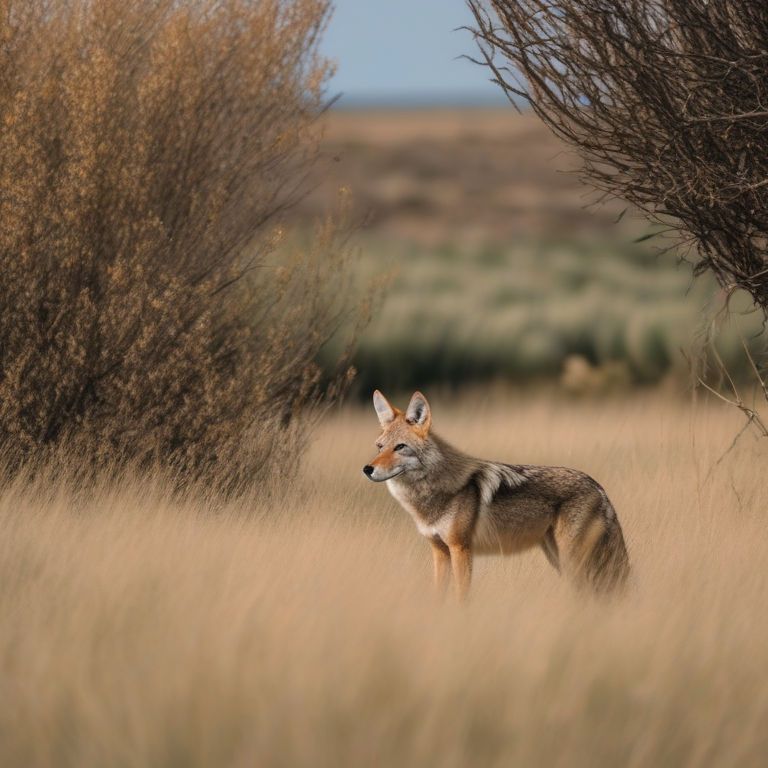

In [ ]:
import torch

prompt = (
    "A realistic documentary wildlife photograph of a coyote "
    "standing in natural grassland, photographed outdoors in natural daylight, "
    "realistic anatomy, realistic fur, natural colours, "
    "authentic wildlife photography"
)

negative_prompt = (
    "cartoon, painting, illustration, drawing, CGI, "
    "text, watermark, logo, extra legs, extra head, "
    "malformed anatomy, deformed animal"
)

generator = torch.Generator(
    device="cuda"
).manual_seed(401001)

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=25,
    guidance_scale=6.5,
    width=768,
    height=768,
    generator=generator
)

test_image = result.images[0]

display(test_image)

In [ ]:
test_path = (
    PILOT_DIR /
    "test_coyote_community.jpg"
)

test_image.save(
    test_path,
    quality=95
)

print("Saved to:")
print(test_path)

Saved to:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/fake/sdxl/pilot/test_coyote_community.jpg


In [ ]:
test_path = PILOT_DIR / "test_coyote_community.jpg"

test_image.save(
    test_path,
    quality=95
)

print("Saved:", test_path)

Saved: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/fake/sdxl/pilot/test_coyote_community.jpg


In [ ]:
FAKE_CATEGORIES = [
    "opossum",
    "raccoon",
    "rabbit",
    "coyote",
    "bobcat",
    "squirrel",
    "skunk"
]

print(FAKE_CATEGORIES)

['opossum', 'raccoon', 'rabbit', 'coyote', 'bobcat', 'squirrel', 'skunk']


In [ ]:
COMMUNITY_PROMPT = (
    "A realistic documentary wildlife photograph of a {animal} "
    "in its natural habitat, photographed outdoors, "
    "natural lighting, realistic anatomy, realistic fur, "
    "natural colours, authentic wildlife photography, "
    "slightly imperfect real-world composition"
)

CAMERA_TRAP_PROMPT = (
    "A realistic motion-triggered trail camera photograph of a {animal} "
    "in its natural habitat, fixed camera viewpoint, "
    "animal not perfectly centred, realistic wildlife behaviour, "
    "slightly lower image quality, natural background, "
    "authentic remote camera trap photograph"
)

NEGATIVE_PROMPT = (
    "cartoon, painting, illustration, drawing, CGI, "
    "text, watermark, logo, extra legs, extra head, "
    "duplicate animal, malformed anatomy, deformed body, "
    "fantasy creature"
)

In [ ]:
import pandas as pd
import torch

pilot_records = []

styles = {
    "community": COMMUNITY_PROMPT,
    "camera_trap": CAMERA_TRAP_PROMPT
}

base_seed = 401000

for animal_index, animal in enumerate(FAKE_CATEGORIES):

    for style_index, (style_name, template) in enumerate(styles.items()):

        seed = (
            base_seed
            + animal_index * 100
            + style_index
        )

        prompt = template.format(
            animal=animal
        )

        print(
            f"Generating {animal} - {style_name}"
        )

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(seed)

        result = pipe(
            prompt=prompt,
            negative_prompt=NEGATIVE_PROMPT,
            num_inference_steps=25,
            guidance_scale=6.5,
            width=768,
            height=768,
            generator=generator
        )

        image = result.images[0]

        filename = (
            f"pilot_{animal}_{style_name}_{seed}.jpg"
        )

        save_path = PILOT_DIR / filename

        image.save(
            save_path,
            quality=95
        )

        pilot_records.append({
            "filename": filename,
            "category": animal,
            "style": style_name,
            "seed": seed,
            "prompt": prompt,
            "negative_prompt": NEGATIVE_PROMPT,
            "model": MODEL_ID,
            "steps": 25,
            "guidance_scale": 6.5,
            "width": 768,
            "height": 768,
            "local_path": str(save_path)
        })

pilot_df = pd.DataFrame(
    pilot_records
)

pilot_df.to_csv(
    ROOT / "metadata/sdxl_pilot_manifest.csv",
    index=False
)

print()
print("DONE")
print("Pilot images generated:", len(pilot_df))

Generating opossum - community


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generating opossum - camera_trap


  0%|          | 0/25 [00:00<?, ?it/s]

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generating skunk - camera_trap


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



DONE
Pilot images generated: 14


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    7,
    2,
    figsize=(10, 25)
)

for row_index, animal in enumerate(FAKE_CATEGORIES):

    for column_index, style in enumerate(
        ["community", "camera_trap"]
    ):

        row = pilot_df[
            (pilot_df["category"] == animal)
            &
            (pilot_df["style"] == style)
        ].iloc[0]

        with Image.open(row["local_path"]) as img:

            axes[row_index][column_index].imshow(
                img
            )

        axes[row_index][column_index].set_title(
            f"{animal.upper()} — {style}"
        )

        axes[row_index][column_index].axis("off")

plt.tight_layout()

pilot_sheet = (
    ROOT /
    "reports/sdxl_pilot_contact_sheet.jpg"
)

plt.savefig(
    pilot_sheet,
    dpi=100,
    bbox_inches="tight"
)

plt.show()

print("Saved:", pilot_sheet)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
COMMUNITY_PROMPT_V2 = (
    "An ordinary real-world wildlife observation photograph of a {animal} "
    "in its natural habitat, taken by a member of the public using a consumer camera, "
    "natural uneven lighting, realistic anatomy and fur, "
    "slightly imperfect framing, animal not necessarily centered, "
    "natural vegetation and background clutter, realistic photographic detail, "
    "documentary wildlife observation photograph"
)

CAMERA_DAY_PROMPT_V2 = (
    "A realistic daytime motion-triggered trail camera photograph of a {animal}, "
    "fixed wide-angle camera viewpoint, animal at medium distance from the camera, "
    "deep depth of field, natural vegetation visible across the frame, "
    "slightly imperfect framing, ordinary daylight, lower contrast, "
    "minor sensor noise, realistic remote wildlife monitoring photograph"
)

CAMERA_NIGHT_PROMPT_V2 = (
    "A realistic nighttime infrared trail camera photograph of a {animal}, "
    "monochrome grayscale infrared image, fixed wide-angle camera viewpoint, "
    "animal at medium distance, harsh infrared illumination, "
    "deep depth of field, vegetation and ground clearly visible, "
    "slight sensor noise and slight motion blur, "
    "imperfect framing, authentic remote wildlife monitoring photograph"
)

NEGATIVE_PROMPT_V2 = (
    "cartoon, illustration, painting, CGI, fantasy, "
    "studio portrait, professional glamour photography, cinematic lighting, "
    "extreme bokeh, very shallow depth of field, perfectly centered portrait, "
    "text, logo, watermark, timestamp, date overlay, camera brand text, "
    "extra legs, extra head, extra tail, duplicate animal, "
    "malformed anatomy, deformed body"
)

In [ ]:
PILOT_V2_DIR = (
    ROOT /
    "raw/fake/sdxl/pilot_v2"
)

PILOT_V2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(PILOT_V2_DIR)

/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/fake/sdxl/pilot_v2


In [ ]:
import pandas as pd
import torch

styles_v2 = {
    "community": COMMUNITY_PROMPT_V2,
    "camera_day": CAMERA_DAY_PROMPT_V2,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_V2
}

pilot_v2_records = []

BASE_SEED = 402000

for animal_index, animal in enumerate(FAKE_CATEGORIES):

    for style_index, (style_name, template) in enumerate(
        styles_v2.items()
    ):

        seed = (
            BASE_SEED
            + animal_index * 100
            + style_index
        )

        prompt = template.format(
            animal=animal
        )

        print(
            f"Generating: {animal} | {style_name}"
        )

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(seed)

        result = pipe(
            prompt=prompt,
            negative_prompt=NEGATIVE_PROMPT_V2,
            num_inference_steps=25,
            guidance_scale=6.5,
            width=768,
            height=768,
            generator=generator
        )

        image = result.images[0]

        filename = (
            f"pilotv2_{animal}_"
            f"{style_name}_{seed}.jpg"
        )

        save_path = (
            PILOT_V2_DIR /
            filename
        )

        image.save(
            save_path,
            quality=95
        )

        pilot_v2_records.append({
            "filename": filename,
            "category": animal,
            "style": style_name,
            "seed": seed,
            "prompt": prompt,
            "negative_prompt":
                NEGATIVE_PROMPT_V2,
            "model": MODEL_ID,
            "steps": 25,
            "guidance_scale": 6.5,
            "generation_width": 768,
            "generation_height": 768,
            "local_path": str(save_path)
        })

pilot_v2_df = pd.DataFrame(
    pilot_v2_records
)

pilot_v2_df.to_csv(
    ROOT /
    "metadata/sdxl_pilot_v2_manifest.csv",
    index=False
)

print()
print(
    "Pilot V2 generated:",
    len(pilot_v2_df)
)

Generating: opossum | community


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generating: opossum | camera_day


  0%|          | 0/25 [00:00<?, ?it/s]

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generating: skunk | camera_night_ir


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



Pilot V2 generated: 21


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

style_order = [
    "community",
    "camera_day",
    "camera_night_ir"
]

fig, axes = plt.subplots(
    7,
    3,
    figsize=(14, 25)
)

for row_index, animal in enumerate(
    FAKE_CATEGORIES
):

    for column_index, style in enumerate(
        style_order
    ):

        row = pilot_v2_df[
            (pilot_v2_df["category"] == animal)
            &
            (pilot_v2_df["style"] == style)
        ].iloc[0]

        with Image.open(
            row["local_path"]
        ) as img:

            axes[
                row_index
            ][
                column_index
            ].imshow(img)

        axes[row_index][column_index].set_title(
            f"{animal.upper()}\n{style}"
        )

        axes[row_index][column_index].axis(
            "off"
        )

plt.tight_layout()

pilot_v2_sheet = (
    ROOT /
    "reports/sdxl_pilot_v2_contact_sheet.jpg"
)

plt.savefig(
    pilot_v2_sheet,
    dpi=100,
    bbox_inches="tight"
)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

In [ ]:
COMMUNITY_PROMPT_FINAL = (
    "An ordinary real-world wildlife observation photograph of a {animal}, "
    "{pose}, in {habitat}, {lighting}, "
    "photographed using a consumer or enthusiast camera, "
    "animal at {distance}, natural vegetation and background clutter, "
    "realistic anatomy and fur, natural colours, "
    "slightly imperfect real-world composition, "
    "documentary wildlife observation photograph"
)

CAMERA_DAY_PROMPT_FINAL = (
    "A genuine-looking daytime motion-triggered trail camera photograph of a {animal}, "
    "{pose}, in {habitat}, fixed unattended wide-angle camera viewpoint, "
    "animal at {distance}, animal occupies only part of the frame, "
    "deep depth of field, background vegetation clearly visible, "
    "ordinary daylight, slightly flat contrast, minor sensor noise, "
    "imperfect framing, remote wildlife monitoring image"
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "A genuine-looking nighttime infrared trail camera photograph of a {animal}, "
    "{pose}, in {habitat}, monochrome grayscale infrared image, "
    "fixed unattended wide-angle camera viewpoint, "
    "animal at {distance}, animal occupies only part of the frame, "
    "deep depth of field, harsh infrared illumination, "
    "visible ground and vegetation, sensor noise, slight motion blur, "
    "imperfect framing, remote wildlife monitoring image"
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, illustration, painting, CGI, fantasy, "
    "studio portrait, glamour photography, cinematic portrait, "
    "extreme bokeh, very shallow depth of field, "
    "perfectly centered animal portrait, "
    "border, white border, black border, picture frame, photo frame, "
    "picture-in-picture, collage, poster, "
    "text, caption, watermark, logo, timestamp, date, camera brand, "
    "extra legs, extra head, extra tail, duplicate animal, "
    "malformed anatomy, deformed body"
)

In [ ]:
HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

In [ ]:
FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

FULL_FAKE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

print(FULL_FAKE_DIR)

/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/fake/sdxl/generated


In [ ]:
import pandas as pd
import torch
import random
from pathlib import Path

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

# Load previous progress if this is a restart
if FULL_MANIFEST.exists():

    existing_df = pd.read_csv(
        FULL_MANIFEST
    )

    generation_records = (
        existing_df.to_dict("records")
    )

    existing_ids = set(
        existing_df["image_id"]
    )

    print(
        "Restoring previous generation:",
        len(existing_ids),
        "images already complete"
    )

else:

    generation_records = []
    existing_ids = set()

print(
    "Target total:",
    sum(STYLE_TARGETS.values())
    * len(ANIMAL_NAMES)
)

Restoring previous generation: 2244 images already complete
Target total: 2345


In [ ]:
BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (category, animal_description) in enumerate(
    animal_items
):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]

        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # Already generated?
            if image_id in existing_ids:
                continue

            # Deterministic prompt variation
            rng = random.Random(seed)

            habitat = rng.choice(
                HABITATS
            )

            pose = rng.choice(
                POSES
            )

            distance = rng.choice(
                DISTANCES
            )

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"{category} | "
                f"{style} | "
                f"{image_number + 1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                output = pipe(
                    prompt=prompt,
                    negative_prompt=
                        NEGATIVE_PROMPT_FINAL,
                    num_inference_steps=25,
                    guidance_scale=6.5,
                    width=768,
                    height=768,
                    generator=generator
                )

                image = output.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id":
                        image_id,

                    "filename":
                        filename,

                    "label":
                        "fake",

                    "category":
                        category,

                    "animal_description":
                        animal_description,

                    "style":
                        style,

                    "model":
                        MODEL_ID,

                    "prompt":
                        prompt,

                    "negative_prompt":
                        NEGATIVE_PROMPT_FINAL,

                    "seed":
                        seed,

                    "steps":
                        25,

                    "guidance_scale":
                        6.5,

                    "generation_width":
                        768,

                    "generation_height":
                        768,

                    "local_path":
                        str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                # SAVE AFTER EVERY IMAGE
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

print("GENERATION LOOP FINISHED")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (86 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CLIPTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['minor sensor noise , imperfect framing , remote wildlife monitoring image']


skunk | camera_day | 70/85


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (86 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['minor sensor noise , imperfect framing , remote wildlife monitoring image']


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['imperfect framing , remote wildlife monitoring image']
The following part of 

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['noise , slight motion blur , imperfect framing , remote wildlife monitoring image']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['noise , slight motion blur , imperfect framing , remote wildlife monitoring image']


skunk | camera_night_ir | 85/85


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


GENERATION LOOP FINISHED


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

print("Project exists:", ROOT.exists())

Mounted at /content/drive
Project exists: True


In [ ]:
import pandas as pd

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

if FULL_MANIFEST.exists():

    progress_df = pd.read_csv(
        FULL_MANIFEST
    )

    print(
        "Generated:",
        len(progress_df),
        "/ 2345"
    )

    print()

    print(
        pd.crosstab(
            progress_df["category"],
            progress_df["style"]
        )
    )

else:
    print("Manifest not found")

Generated: 182 / 2345

style     camera_day  community
category                       
opossum           17        165


In [ ]:
FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

generated_files = list(
    FULL_FAKE_DIR.glob("*.jpg")
)

print(
    "Actual generated JPG files:",
    len(generated_files)
)

Actual generated JPG files: 182


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

CUDA available: True
GPU: Tesla T4


In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

MODEL_ID = (
    "stabilityai/"
    "stable-diffusion-xl-base-1.0"
)

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)

pipe.enable_model_cpu_offload()

pipe.vae.enable_slicing()

print("SDXL READY")

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL READY


In [ ]:
import random

ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "An ordinary real-world wildlife observation photograph of a {animal}, "
    "{pose}, in {habitat}, {lighting}, "
    "photographed using a consumer or enthusiast camera, "
    "animal at {distance}, natural vegetation and background clutter, "
    "realistic anatomy and fur, natural colours, "
    "slightly imperfect real-world composition, "
    "documentary wildlife observation photograph"
)

CAMERA_DAY_PROMPT_FINAL = (
    "A genuine-looking daytime motion-triggered trail camera photograph of a {animal}, "
    "{pose}, in {habitat}, fixed unattended wide-angle camera viewpoint, "
    "animal at {distance}, animal occupies only part of the frame, "
    "deep depth of field, background vegetation clearly visible, "
    "ordinary daylight, slightly flat contrast, minor sensor noise, "
    "imperfect framing, remote wildlife monitoring image"
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "A genuine-looking nighttime infrared trail camera photograph of a {animal}, "
    "{pose}, in {habitat}, monochrome grayscale infrared image, "
    "fixed unattended wide-angle camera viewpoint, "
    "animal at {distance}, animal occupies only part of the frame, "
    "deep depth of field, harsh infrared illumination, "
    "visible ground and vegetation, sensor noise, slight motion blur, "
    "imperfect framing, remote wildlife monitoring image"
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, illustration, painting, CGI, fantasy, "
    "studio portrait, glamour photography, cinematic portrait, "
    "extreme bokeh, very shallow depth of field, "
    "perfectly centered animal portrait, "
    "border, white border, black border, picture frame, photo frame, "
    "picture-in-picture, collage, poster, "
    "text, caption, watermark, logo, timestamp, date, camera brand, "
    "extra legs, extra head, extra tail, duplicate animal, "
    "malformed anatomy, deformed body"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

In [ ]:
FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

FULL_FAKE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if FULL_MANIFEST.exists():

    existing_df = pd.read_csv(
        FULL_MANIFEST
    )

    generation_records = (
        existing_df.to_dict("records")
    )

    existing_ids = set(
        existing_df["image_id"]
    )

    print(
        "Already completed:",
        len(existing_ids),
        "/ 2345"
    )

else:

    generation_records = []
    existing_ids = set()

    print("No previous progress found")

Already completed: 182 / 2345


In [ ]:
BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (
    category,
    animal_description
) in enumerate(animal_items):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]

        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # THIS IS WHAT MAKES RESUME WORK
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(
                HABITATS
            )

            pose = rng.choice(
                POSES
            )

            distance = rng.choice(
                DISTANCES
            )

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                category,
                style,
                image_number + 1,
                "/",
                target
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                output = pipe(
                    prompt=prompt,
                    negative_prompt=NEGATIVE_PROMPT_FINAL,
                    num_inference_steps=25,
                    guidance_scale=6.5,
                    width=768,
                    height=768,
                    generator=generator
                )

                image = output.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt": NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

print("GENERATION FINISHED")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (86 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CLIPTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['minor sensor noise , imperfect framing , remote wildlife monitoring image']


opossum camera_day 18 / 85


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (86 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['minor sensor noise , imperfect framing , remote wildlife monitoring image']


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['contrast , minor sensor noise , imperfect framing , remote wildlife monitorin

...

  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['contrast , minor sensor noise , imperfect framing , remote wildlife monitoring image']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['contrast , minor sensor noise , imperfect framing , remote wildlife monitoring image']


opossum camera_day 29 / 85


  0%|          | 0/25 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

In [ ]:
STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

In [ ]:
test_prompt = CAMERA_DAY_PROMPT_FINAL.format(
    animal="North American coyote, Canis latrans",
    pose="walking naturally",
    habitat="woodland",
    distance="medium distance from the camera"
)

tokens = pipe.tokenizer(
    test_prompt,
    truncation=False
)["input_ids"]

print("Prompt tokens:", len(tokens))
print(test_prompt)

Prompt tokens: 55
Daytime trail-camera photo of North American coyote, Canis latrans, walking naturally, in woodland. Fixed wide-angle camera, animal at medium distance from the camera, deep depth of field, visible vegetation, flat daylight, minor sensor noise and imperfect framing.


In [ ]:
negative_tokens = pipe.tokenizer(
    NEGATIVE_PROMPT_FINAL,
    truncation=False
)["input_ids"]

print(
    "Negative prompt tokens:",
    len(negative_tokens)
)

Negative prompt tokens: 50


In [ ]:
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = existing_df.to_dict(
    "records"
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Already saved:",
    len(existing_ids)
)

Already saved: 193


In [ ]:
def token_count(tokenizer, text):
    return len(
        tokenizer(
            text,
            truncation=False
        )["input_ids"]
    )

existing_df["prompt_tokens_1"] = existing_df["prompt"].apply(
    lambda x: token_count(pipe.tokenizer, x)
)

if hasattr(pipe, "tokenizer_2") and pipe.tokenizer_2 is not None:
    existing_df["prompt_tokens_2"] = existing_df["prompt"].apply(
        lambda x: token_count(pipe.tokenizer_2, x)
    )
else:
    existing_df["prompt_tokens_2"] = existing_df["prompt_tokens_1"]

existing_df["prompt_too_long"] = (
    (existing_df["prompt_tokens_1"] > 77)
    |
    (existing_df["prompt_tokens_2"] > 77)
)

print("Total saved:", len(existing_df))

print(
    "Safe prompts:",
    (~existing_df["prompt_too_long"]).sum()
)

print(
    "Overlong prompts:",
    existing_df["prompt_too_long"].sum()
)

print()

print(
    existing_df[
        [
            "category",
            "style",
            "prompt_tokens_1",
            "prompt_tokens_2",
            "prompt_too_long"
        ]
    ].head(20)
)

Total saved: 193
Safe prompts: 129
Overlong prompts: 64

   category      style  prompt_tokens_1  prompt_tokens_2  prompt_too_long
0   opossum  community               74               74            False
1   opossum  community               78               78             True
2   opossum  community               77               77            False
3   opossum  community               77               77            False
4   opossum  community               74               74            False
5   opossum  community               73               73            False
6   opossum  community               76               76            False
7   opossum  community               76               76            False
8   opossum  community               76               76            False
9   opossum  community               75               75            False
10  opossum  community               77               77            False
11  opossum  community               78               7

In [ ]:
import shutil
from pathlib import Path

ARCHIVE_DIR = (
    ROOT /
    "raw/fake/sdxl/archive_overlong_prompt"
)

ARCHIVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

bad_rows = existing_df[
    existing_df["prompt_too_long"]
].copy()

print(
    "Archiving:",
    len(bad_rows),
    "images"
)

for _, row in bad_rows.iterrows():

    old_path = Path(row["local_path"])

    if old_path.exists():

        new_path = (
            ARCHIVE_DIR /
            old_path.name
        )

        shutil.move(
            str(old_path),
            str(new_path)
        )

print("Archive complete.")

Archiving: 64 images
Archive complete.


In [ ]:
# Backup original manifest first
backup_manifest = (
    ROOT /
    "metadata/sdxl_manifest_before_prompt_cleanup.csv"
)

existing_df.to_csv(
    backup_manifest,
    index=False
)

# Remove rows whose prompts were too long
clean_existing_df = existing_df[
    ~existing_df["prompt_too_long"]
].copy()

# Remove temporary audit columns
clean_existing_df = clean_existing_df.drop(
    columns=[
        "prompt_tokens_1",
        "prompt_tokens_2",
        "prompt_too_long"
    ],
    errors="ignore"
)

clean_existing_df.to_csv(
    FULL_MANIFEST,
    index=False
)

print(
    "Valid images remaining:",
    len(clean_existing_df)
)

Valid images remaining: 129


In [ ]:
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = (
    existing_df.to_dict("records")
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Ready to resume from:",
    len(existing_ids),
    "/ 2345"
)

print(
    f"{len(existing_ids) / 2345 * 100:.1f}% complete"
)

Ready to resume from: 129 / 2345
5.5% complete


In [ ]:
variables_to_check = [
    "COMMUNITY_PROMPT_FINAL",
    "CAMERA_DAY_PROMPT_FINAL",
    "CAMERA_NIGHT_PROMPT_FINAL",
    "NEGATIVE_PROMPT_FINAL",
    "STYLE_TEMPLATES",
    "STYLE_TARGETS",
    "ANIMAL_NAMES",
    "HABITATS",
    "POSES",
    "DISTANCES",
    "COMMUNITY_LIGHTING"
]

for name in variables_to_check:

    print(
        name,
        "✅"
        if name in globals()
        else "❌ MISSING"
    )

COMMUNITY_PROMPT_FINAL ✅
CAMERA_DAY_PROMPT_FINAL ✅
CAMERA_NIGHT_PROMPT_FINAL ✅
NEGATIVE_PROMPT_FINAL ✅
STYLE_TEMPLATES ✅
STYLE_TARGETS ✅
ANIMAL_NAMES ✅
HABITATS ✅
POSES ✅
DISTANCES ✅
COMMUNITY_LIGHTING ✅


In [ ]:
test_animal = (
    "North American bobcat, Lynx rufus, short tail"
)

test_pose = (
    "partially obscured by vegetation"
)

test_habitat = (
    "leaf-covered woodland floor"
)

test_distance = (
    "several metres from the camera"
)

test_lighting = (
    "late afternoon light"
)

test_prompts = {
    "community":
        COMMUNITY_PROMPT_FINAL.format(
            animal=test_animal,
            pose=test_pose,
            habitat=test_habitat,
            lighting=test_lighting,
            distance=test_distance
        ),

    "camera_day":
        CAMERA_DAY_PROMPT_FINAL.format(
            animal=test_animal,
            pose=test_pose,
            habitat=test_habitat,
            distance=test_distance
        ),

    "camera_night_ir":
        CAMERA_NIGHT_PROMPT_FINAL.format(
            animal=test_animal,
            pose=test_pose,
            habitat=test_habitat,
            distance=test_distance
        )
}

for style, prompt in test_prompts.items():

    count = len(
        pipe.tokenizer(
            prompt,
            truncation=False
        )["input_ids"]
    )

    print(
        style,
        "tokens:",
        count
    )

community tokens: 58
camera_day tokens: 63
camera_night_ir tokens: 68


In [ ]:
import random
import torch
import pandas as pd

BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (
    category,
    animal_description
) in enumerate(animal_items):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]

        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # VERY IMPORTANT:
            # skip images already generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(
                HABITATS
            )

            pose = rng.choice(
                POSES
            )

            distance = rng.choice(
                DISTANCES
            )

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            current_number = (
                len(existing_ids) + 1
            )

            print(
                f"\nOverall: "
                f"{current_number}/2345"
            )

            print(
                f"{category} | "
                f"{style} | "
                f"{image_number + 1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                output = pipe(
                    prompt=prompt,
                    negative_prompt=
                        NEGATIVE_PROMPT_FINAL,
                    num_inference_steps=25,
                    guidance_scale=6.5,
                    width=768,
                    height=768,
                    generator=generator
                )

                image = output.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id":
                        image_id,

                    "filename":
                        filename,

                    "label":
                        "fake",

                    "category":
                        category,

                    "animal_description":
                        animal_description,

                    "style":
                        style,

                    "model":
                        MODEL_ID,

                    "prompt":
                        prompt,

                    "negative_prompt":
                        NEGATIVE_PROMPT_FINAL,

                    "seed":
                        seed,

                    "steps":
                        25,

                    "guidance_scale":
                        6.5,

                    "generation_width":
                        768,

                    "generation_height":
                        768,

                    "local_path":
                        str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                # Save progress after EVERY image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

print("\nGENERATION FINISHED")


Overall: 130/2345
opossum | community | 2/165


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



Overall: 131/2345
opossum | community | 12/165


  0%|          | 0/25 [00:00<?, ?it/s]

...


Overall: 488/2345
raccoon | community | 153/165


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



Overall: 489/2345
raccoon | community | 154/165


  0%|          | 0/25 [00:00<?, ?it/s]

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

print("Project exists:", ROOT.exists())

Mounted at /content/drive
Project exists: True


In [ ]:
import pandas as pd

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

progress_df = pd.read_csv(
    FULL_MANIFEST
)

completed = len(progress_df)

print(
    "Saved:",
    completed,
    "/ 2345"
)

print(
    f"Progress: "
    f"{completed / 2345 * 100:.1f}%"
)

print()

print(
    pd.crosstab(
        progress_df["category"],
        progress_df["style"]
    )
)

Saved: 572 / 2345
Progress: 24.4%

style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
raccoon           72                0        165


In [ ]:
FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

files = list(
    FULL_FAKE_DIR.glob("*.jpg")
)

print(
    "Actual JPG files:",
    len(files)
)

Actual JPG files: 572


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

CUDA available: True
GPU: Tesla T4


In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

MODEL_ID = (
    "stabilityai/"
    "stable-diffusion-xl-base-1.0"
)

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)

pipe.enable_model_cpu_offload()

pipe.vae.enable_slicing()

print("SDXL READY")

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

In [ ]:
try:
    print("pipe exists:", type(pipe))
    print("existing IDs:", len(existing_ids))
except Exception as e:
    print("Runtime state was lost:", e)

Runtime state was lost: name 'pipe' is not defined


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

progress_df = pd.read_csv(
    FULL_MANIFEST
)

print(
    "Manifest images:",
    len(progress_df),
    "/ 2345"
)

print(
    f"Progress: "
    f"{len(progress_df) / 2345 * 100:.1f}%"
)

jpg_files = list(
    FULL_FAKE_DIR.glob("*.jpg")
)

print(
    "Actual JPG files:",
    len(jpg_files)
)

Mounted at /content/drive
Manifest images: 572 / 2345
Progress: 24.4%
Actual JPG files: 572


In [ ]:
print(
    pd.crosstab(
        progress_df["category"],
        progress_df["style"]
    )
)

style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
raccoon           72                0        165


In [ ]:
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        torch.cuda.get_device_name(0)
    )

CUDA available: True
Tesla T4


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

MODEL_ID = (
    "stabilityai/"
    "stable-diffusion-xl-base-1.0"
)

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)

pipe.enable_model_cpu_offload()
pipe.vae.enable_slicing()

print("SDXL READY")

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL READY


In [ ]:
import random
import pandas as pd
import torch

ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

print("Generation settings restored.")

Generation settings restored.


In [ ]:
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = (
    existing_df.to_dict("records")
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Already completed:",
    len(existing_ids),
    "/ 2345"
)

print(
    f"Progress: "
    f"{len(existing_ids) / 2345 * 100:.1f}%"
)

Already completed: 572 / 2345
Progress: 24.4%


In [ ]:
test_animal = "North American bobcat, Lynx rufus, short tail"
test_pose = "partially obscured by vegetation"
test_habitat = "leaf-covered woodland floor"
test_distance = "several metres from the camera"
test_lighting = "late afternoon light"

test_prompts = {
    "community": COMMUNITY_PROMPT_FINAL.format(
        animal=test_animal,
        pose=test_pose,
        habitat=test_habitat,
        lighting=test_lighting,
        distance=test_distance
    ),

    "camera_day": CAMERA_DAY_PROMPT_FINAL.format(
        animal=test_animal,
        pose=test_pose,
        habitat=test_habitat,
        distance=test_distance
    ),

    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL.format(
        animal=test_animal,
        pose=test_pose,
        habitat=test_habitat,
        distance=test_distance
    )
}

for style, prompt in test_prompts.items():

    tokens = pipe.tokenizer(
        prompt,
        truncation=False
    )["input_ids"]

    print(
        style,
        len(tokens),
        "tokens"
    )

negative_tokens = pipe.tokenizer(
    NEGATIVE_PROMPT_FINAL,
    truncation=False
)["input_ids"]

print(
    "negative prompt:",
    len(negative_tokens),
    "tokens"
)

community 58 tokens
camera_day 63 tokens
camera_night_ir 68 tokens
negative prompt: 50 tokens


In [ ]:
BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (
    category,
    animal_description
) in enumerate(animal_items):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # Skip everything already generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(HABITATS)
            pose = rng.choice(POSES)
            distance = rng.choice(DISTANCES)

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"\nOverall: "
                f"{len(existing_ids)+1}/2345"
            )

            print(
                f"{category} | "
                f"{style} | "
                f"{image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                output = pipe(
                    prompt=prompt,
                    negative_prompt=NEGATIVE_PROMPT_FINAL,
                    num_inference_steps=25,
                    guidance_scale=6.5,
                    width=768,
                    height=768,
                    generator=generator
                )

                image = output.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt": NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                # Save after EVERY image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

print("\nGENERATION FINISHED")


Overall: 573/2345
raccoon | camera_day | 73/85


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



Overall: 574/2345
raccoon | camera_day | 74/85


  0%|          | 0/25 [00:00<?, ?it/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



Overall: 796/2345
rabbit | community | 126/165


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

progress_df = pd.read_csv(
    FULL_MANIFEST
)

jpg_files = list(
    FULL_FAKE_DIR.glob("*.jpg")
)

print(
    "Manifest:",
    len(progress_df),
    "/ 2345"
)

print(
    "Actual JPGs:",
    len(jpg_files)
)

print(
    f"Progress: "
    f"{len(progress_df)/2345*100:.1f}%"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Manifest: 795 / 2345
Actual JPGs: 795
Progress: 33.9%


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

MODEL_ID = (
    "stabilityai/"
    "stable-diffusion-xl-base-1.0"
)

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
    low_cpu_mem_usage=True
)

# Put the model directly on the T4 GPU
pipe = pipe.to("cuda")

# Reduce memory during VAE decoding
pipe.vae.enable_slicing()

# Reduce attention memory
pipe.enable_attention_slicing("max")

# Hide the inner 25-step progress bars
pipe.set_progress_bar_config(
    disable=True
)

print("SDXL READY - GPU MODE")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL READY - GPU MODE


In [ ]:
import psutil
import torch

ram = psutil.virtual_memory()

print(
    f"System RAM used: "
    f"{ram.percent}%"
)

print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated()/1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved()/1024**3:.2f} GB"
)

System RAM used: 53.3%
GPU allocated: 6.57 GB
GPU reserved: 6.84 GB


In [ ]:
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = (
    existing_df.to_dict("records")
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Resuming from:",
    len(existing_ids),
    "/ 2345"
)

Resuming from: 795 / 2345


In [ ]:
import random
import torch
import pandas as pd
import gc

BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (
    category,
    animal_description
) in enumerate(animal_items):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # Skip already finished images
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(
                HABITATS
            )

            pose = rng.choice(
                POSES
            )

            distance = rng.choice(
                DISTANCES
            )

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"Overall: "
                f"{len(existing_ids)+1}/2345 "
                f"| {category} "
                f"| {style} "
                f"| {image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                with torch.inference_mode():

                    result = pipe(
                        prompt=prompt,
                        negative_prompt=
                            NEGATIVE_PROMPT_FINAL,
                        num_inference_steps=25,
                        guidance_scale=6.5,
                        width=768,
                        height=768,
                        generator=generator
                    )

                image = result.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description":
                        animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt":
                        NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path":
                        str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

                # IMPORTANT MEMORY CLEANUP
                del result
                del image
                del generator

                torch.cuda.empty_cache()

                # Clean Python RAM every 5 images
                if len(existing_ids) % 5 == 0:
                    gc.collect()

            except torch.cuda.OutOfMemoryError:

                print(
                    "GPU MEMORY ERROR - "
                    "cleaning and continuing"
                )

                torch.cuda.empty_cache()
                gc.collect()

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

                torch.cuda.empty_cache()
                gc.collect()

print(
    "\nGENERATION FINISHED"
)

NameError: name 'ANIMAL_NAMES' is not defined

In [ ]:
import random
import pandas as pd
import torch

ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

print("Generation configuration restored.")

Generation configuration restored.


In [ ]:
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = (
    existing_df.to_dict("records")
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Already completed:",
    len(existing_ids),
    "/ 2345"
)

print(
    f"Progress: "
    f"{len(existing_ids) / 2345 * 100:.1f}%"
)

Already completed: 795 / 2345
Progress: 33.9%


In [ ]:
print(type(pipe))

<class 'diffusers.pipelines.stable_diffusion_xl.pipeline_stable_diffusion_xl.StableDiffusionXLPipeline'>


In [ ]:
from pathlib import Path
import pandas as pd
import random
import torch
import gc

# Project paths
ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

FULL_FAKE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Wildlife categories
ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

# Short prompts — keeps us below CLIP's token limit
COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

# Reload your saved progress
existing_df = pd.read_csv(
    FULL_MANIFEST
)

generation_records = (
    existing_df.to_dict("records")
)

existing_ids = set(
    existing_df["image_id"]
)

print(
    "Saved progress:",
    len(existing_ids),
    "/ 2345"
)

print(
    f"{len(existing_ids) / 2345 * 100:.1f}% complete"
)

print()

print(
    pd.crosstab(
        existing_df["category"],
        existing_df["style"]
    )
)

Saved progress: 795 / 2345
33.9% complete

style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
rabbit             0                0        125
raccoon           85               85        165


In [ ]:
print(
    "Pipeline device:",
    pipe._execution_device
)

Pipeline device: cuda:0


In [ ]:
BASE_SEED = 500000

animal_items = list(
    ANIMAL_NAMES.items()
)

style_names = list(
    STYLE_TARGETS.keys()
)

for animal_index, (
    category,
    animal_description
) in enumerate(animal_items):

    for style_index, style in enumerate(
        style_names
    ):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = (
                f"sdxl_{category}_"
                f"{style}_{seed}"
            )

            # Skip everything already generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(HABITATS)
            pose = rng.choice(POSES)
            distance = rng.choice(DISTANCES)

            if style == "community":

                lighting = rng.choice(
                    COMMUNITY_LIGHTING
                )

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"Overall: "
                f"{len(existing_ids)+1}/2345 "
                f"| {category} "
                f"| {style} "
                f"| {image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                with torch.inference_mode():

                    result = pipe(
                        prompt=prompt,
                        negative_prompt=
                            NEGATIVE_PROMPT_FINAL,
                        num_inference_steps=25,
                        guidance_scale=6.5,
                        width=768,
                        height=768,
                        generator=generator
                    )

                image = result.images[0]

                filename = (
                    f"{image_id}.jpg"
                )

                save_path = (
                    FULL_FAKE_DIR /
                    filename
                )

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt":
                        NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(
                    image_id
                )

                # Save progress after each image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

                # Memory cleanup
                del result
                del image
                del generator

                torch.cuda.empty_cache()

                if len(existing_ids) % 5 == 0:
                    gc.collect()

            except torch.cuda.OutOfMemoryError:

                print(
                    "GPU memory warning - cleaning memory"
                )

                torch.cuda.empty_cache()
                gc.collect()

            except Exception as e:

                print(
                    "FAILED:",
                    image_id,
                    str(e)
                )

                torch.cuda.empty_cache()
                gc.collect()

print(
    "\nGENERATION FINISHED"
)

Overall: 796/2345 | rabbit | community | 126/165


/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 797/2345 | rabbit | community | 127/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 798/2345 | rabbit | community | 128/165


...

Overall: 833/2345 | rabbit | community | 163/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 834/2345 | rabbit | community | 164/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 835/2345 | rabbit | community | 165/165


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount('/content/drive')

ROOT = Path(
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake"
)

FULL_MANIFEST = (
    ROOT /
    "metadata/sdxl_full_generation_manifest.csv"
)

FULL_FAKE_DIR = (
    ROOT /
    "raw/fake/sdxl/generated"
)

progress_df = pd.read_csv(FULL_MANIFEST)

print("Saved:", len(progress_df), "/ 2345")
print(f"Progress: {len(progress_df)/2345*100:.1f}%")
print(
    "Actual JPG files:",
    len(list(FULL_FAKE_DIR.glob("*.jpg")))
)

print()

print(
    pd.crosstab(
        progress_df["category"],
        progress_df["style"]
    )
)

Mounted at /content/drive
Saved: 834 / 2345
Progress: 35.6%
Actual JPG files: 834

style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
rabbit             0                0        164
raccoon           85               85        165


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
!nvidia-smi

Tue Sep  8 10:14:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount('/content/drive')

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

FULL_MANIFEST = ROOT / "metadata/sdxl_full_generation_manifest.csv"
FULL_FAKE_DIR = ROOT / "raw/fake/sdxl/generated"

FULL_FAKE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT exists:", ROOT.exists())
print("Manifest exists:", FULL_MANIFEST.exists())
print("Fake dir exists:", FULL_FAKE_DIR.exists())

Mounted at /content/drive
ROOT exists: True
Manifest exists: True
Fake dir exists: True


In [ ]:
progress_df = pd.read_csv(FULL_MANIFEST)

print("Manifest images:", len(progress_df), "/ 2345")

jpg_files = list(FULL_FAKE_DIR.glob("*.jpg"))
print("Actual JPG files:", len(jpg_files))

print("\nProgress table:")
print(pd.crosstab(progress_df["category"], progress_df["style"]))

Manifest images: 834 / 2345
Actual JPG files: 834

Progress table:
style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
rabbit             0                0        164
raccoon           85               85        165


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch
from diffusers import StableDiffusionXLPipeline

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("SDXL READY")

CUDA available: True
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL READY


In [ ]:
ANIMAL_NAMES = {
    "opossum": "Virginia opossum",
    "raccoon": "raccoon",
    "rabbit": "cottontail rabbit",
    "coyote": "coyote",
    "bobcat": "bobcat",
    "squirrel": "tree squirrel",
    "skunk": "striped skunk"
}

STYLE_DESCRIPTIONS = {
    "camera_day": "realistic daytime camera-trap wildlife photo",
    "camera_night_ir": "realistic infrared night camera-trap wildlife photo, monochrome",
    "community": "realistic citizen-science wildlife photo taken outdoors"
}

NEGATIVE_PROMPT = (
    "cartoon, painting, illustration, CGI, fantasy, extra limbs, extra ears, "
    "deformed anatomy, blurry animal, duplicate animal, watermark, text, frame, collage"
)

print("Animal names loaded.")

Animal names loaded.


In [ ]:
import os
from PIL import Image
from tqdm.auto import tqdm

existing_df = pd.read_csv(FULL_MANIFEST)
existing_ids = set(existing_df["image_id"].astype(str))
generation_records = existing_df.to_dict("records")

print("Already saved:", len(existing_ids))

Already saved: 834


In [ ]:
plan_path = ROOT / "metadata/sdxl_generation_plan.csv"
print("Plan exists:", plan_path.exists())

Plan exists: False


In [ ]:
import random
import pandas as pd
import torch
import gc

ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

BASE_SEED = 500000

print("Original generation settings restored.")

Original generation settings restored.


In [ ]:
existing_df = pd.read_csv(FULL_MANIFEST)

generation_records = existing_df.to_dict("records")
existing_ids = set(existing_df["image_id"].astype(str))

print("Already completed:", len(existing_ids), "/ 2345")
print(f"Progress: {len(existing_ids)/2345*100:.1f}%")

print()
print(pd.crosstab(
    existing_df["category"],
    existing_df["style"]
))

Already completed: 834 / 2345
Progress: 35.6%

style     camera_day  camera_night_ir  community
category                                        
opossum           85               85        165
rabbit             0                0        164
raccoon           85               85        165


In [ ]:
animal_items = list(ANIMAL_NAMES.items())
style_names = list(STYLE_TARGETS.keys())

for animal_index, (category, animal_description) in enumerate(animal_items):

    for style_index, style in enumerate(style_names):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = f"sdxl_{category}_{style}_{seed}"

            # Skip images already generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(HABITATS)
            pose = rng.choice(POSES)
            distance = rng.choice(DISTANCES)

            if style == "community":

                lighting = rng.choice(COMMUNITY_LIGHTING)

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"Overall: {len(existing_ids)+1}/2345 "
                f"| {category} | {style} "
                f"| {image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                with torch.inference_mode():

                    result = pipe(
                        prompt=prompt,
                        negative_prompt=NEGATIVE_PROMPT_FINAL,
                        num_inference_steps=25,
                        guidance_scale=6.5,
                        width=768,
                        height=768,
                        generator=generator
                    )

                image = result.images[0]

                filename = f"{image_id}.jpg"
                save_path = FULL_FAKE_DIR / filename

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt": NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(image_id)

                # Save progress after every successful image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

                del result
                del image
                del generator

                torch.cuda.empty_cache()

                if len(existing_ids) % 5 == 0:
                    gc.collect()

            except torch.cuda.OutOfMemoryError:

                print("GPU memory warning - cleaning memory")
                torch.cuda.empty_cache()
                gc.collect()

            except Exception as e:

                print("FAILED:", image_id, str(e))
                torch.cuda.empty_cache()
                gc.collect()

Overall: 835/2345 | rabbit | community | 165/165


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 836/2345 | rabbit | camera_day | 1/85


  0%|          | 0/25 [00:00<?, ?it/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 1201/2345 | coyote | camera_day | 31/85


  0%|          | 0/25 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount('/content/drive')

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

FULL_MANIFEST = ROOT / "metadata/sdxl_full_generation_manifest.csv"
FULL_FAKE_DIR = ROOT / "raw/fake/sdxl/generated"

progress_df = pd.read_csv(FULL_MANIFEST)

print("Manifest records:", len(progress_df), "/ 2345")
print("Actual JPG files:", len(list(FULL_FAKE_DIR.glob("*.jpg"))))
print(f"Progress: {len(progress_df)/2345*100:.1f}%")

print()
print(pd.crosstab(
    progress_df["category"],
    progress_df["style"]
))

Mounted at /content/drive
Manifest records: 1200 / 2345
Actual JPG files: 1200
Progress: 51.2%

style     camera_day  camera_night_ir  community
category                                        
coyote            30                0        165
opossum           85               85        165
rabbit            85               85        165
raccoon           85               85        165


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
import torch
import random
import gc

from diffusers import StableDiffusionXLPipeline

MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
    low_cpu_mem_usage=True
)

pipe = pipe.to("cuda")

pipe.vae.enable_slicing()
pipe.enable_attention_slicing("max")
pipe.set_progress_bar_config(disable=True)

print("SDXL READY")
print("Device:", pipe._execution_device)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL READY
Device: cuda:0


In [ ]:
ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

BASE_SEED = 500000

print("Generation settings restored.")

Generation settings restored.


In [ ]:
existing_df = pd.read_csv(FULL_MANIFEST)

generation_records = existing_df.to_dict("records")
existing_ids = set(existing_df["image_id"].astype(str))

print("Already completed:", len(existing_ids), "/ 2345")
print(f"Progress: {len(existing_ids)/2345*100:.1f}%")

Already completed: 1200 / 2345
Progress: 51.2%


In [ ]:
animal_items = list(ANIMAL_NAMES.items())
style_names = list(STYLE_TARGETS.keys())

for animal_index, (category, animal_description) in enumerate(animal_items):

    for style_index, style in enumerate(style_names):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = f"sdxl_{category}_{style}_{seed}"

            # Skip all images that are already safely generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(HABITATS)
            pose = rng.choice(POSES)
            distance = rng.choice(DISTANCES)

            if style == "community":

                lighting = rng.choice(COMMUNITY_LIGHTING)

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"Overall: {len(existing_ids)+1}/2345 "
                f"| {category} | {style} "
                f"| {image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                with torch.inference_mode():

                    result = pipe(
                        prompt=prompt,
                        negative_prompt=NEGATIVE_PROMPT_FINAL,
                        num_inference_steps=25,
                        guidance_scale=6.5,
                        width=768,
                        height=768,
                        generator=generator
                    )

                image = result.images[0]

                filename = f"{image_id}.jpg"
                save_path = FULL_FAKE_DIR / filename

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt": NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(image_id)

                # Save manifest after EVERY completed image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

                del result
                del image
                del generator

                torch.cuda.empty_cache()

                if len(existing_ids) % 5 == 0:
                    gc.collect()

            except torch.cuda.OutOfMemoryError:

                print("GPU memory warning - cleaning memory")
                torch.cuda.empty_cache()
                gc.collect()

            except Exception as e:

                print("FAILED:", image_id, str(e))
                torch.cuda.empty_cache()
                gc.collect()

Overall: 1201/2345 | coyote | camera_day | 31/85


/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 1202/2345 | coyote | camera_day | 32/85


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 1203/2345 | coyote | camera_day | 33/85


...

Overall: 1398/2345 | bobcat | community | 58/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 1399/2345 | bobcat | community | 59/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 1400/2345 | bobcat | community | 60/165


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

FULL_MANIFEST = ROOT / "metadata/sdxl_full_generation_manifest.csv"
FULL_FAKE_DIR = ROOT / "raw/fake/sdxl/generated"

progress_df = pd.read_csv(FULL_MANIFEST)

print("Manifest records:", len(progress_df), "/ 2345")
print("Actual JPG files:", len(list(FULL_FAKE_DIR.glob("*.jpg"))))
print(f"Progress: {len(progress_df)/2345*100:.1f}%")

print()
print(pd.crosstab(
    progress_df["category"],
    progress_df["style"]
))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

print("ROOT exists:", ROOT.exists())
print("Metadata exists:", (ROOT / "metadata").exists())
print("Fake folder exists:", (ROOT / "raw/fake/sdxl/generated").exists())

ROOT exists: True
Metadata exists: True
Fake folder exists: True


In [ ]:
FULL_MANIFEST = ROOT / "metadata/sdxl_full_generation_manifest.csv"

print("Manifest path:")
print(FULL_MANIFEST)

print("\nManifest exists:", FULL_MANIFEST.exists())


Manifest path:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv

Manifest exists: True


In [ ]:
progress_df = pd.read_csv(FULL_MANIFEST)

print("Manifest records:", len(progress_df), "/ 2345)

SyntaxError: unterminated string literal (detected at line 3) (3888231720.py, line 3)

In [ ]:
import pandas as pd

progress_df = pd.read_csv(FULL_MANIFEST)

print("Manifest records:", len(progress_df), "/ 2345")

jpg_files = list(FULL_FAKE_DIR.glob("*.jpg"))
print("Actual JPG files:", len(jpg_files))

print(f"Progress: {len(progress_df)/2345*100:.1f}%")

print()
print(pd.crosstab(
    progress_df["category"],
    progress_df["style"]
))

Manifest records: 1457 / 2345
Actual JPG files: 1457
Progress: 62.1%

style     camera_day  camera_night_ir  community
category                                        
bobcat             0                0        117
coyote            85               85        165
opossum           85               85        165
rabbit            85               85        165
raccoon           85               85        165


In [ ]:
print(type(pipe))

NameError: name 'pipe' is not defined

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch
import random
import gc

drive.mount('/content/drive')

ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")

FULL_MANIFEST = ROOT / "metadata/sdxl_full_generation_manifest.csv"
FULL_FAKE_DIR = ROOT / "raw/fake/sdxl/generated"

print("Manifest exists:", FULL_MANIFEST.exists())
print("Fake folder exists:", FULL_FAKE_DIR.exists())

progress_df = pd.read_csv(FULL_MANIFEST)

print("Already saved:", len(progress_df), "/ 2345")
print("JPG files:", len(list(FULL_FAKE_DIR.glob("*.jpg"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Manifest exists: True
Fake folder exists: True
Already saved: 1999 / 2345
JPG files: 1999


In [ ]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q diffusers transformers accelerate safetensors

In [ ]:
from diffusers import StableDiffusionXLPipeline

MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
    low_cpu_mem_usage=True
)

pipe = pipe.to("cuda")

pipe.vae.enable_slicing()
pipe.enable_attention_slicing("max")
pipe.set_progress_bar_config(disable=True)

print("SDXL READY")
print(type(pipe))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL READY
<class 'diffusers.pipelines.stable_diffusion_xl.pipeline_stable_diffusion_xl.StableDiffusionXLPipeline'>


In [ ]:
ANIMAL_NAMES = {
    "opossum": "Virginia opossum, Didelphis virginiana",
    "raccoon": "common raccoon, Procyon lotor",
    "rabbit": "cottontail rabbit, Sylvilagus",
    "coyote": "North American coyote, Canis latrans",
    "bobcat": "North American bobcat, Lynx rufus, short tail",
    "squirrel": "North American tree squirrel, Sciurus",
    "skunk": "striped skunk, Mephitis mephitis"
}

COMMUNITY_PROMPT_FINAL = (
    "Realistic wildlife observation photo of {animal}, {pose}, "
    "in {habitat}, {lighting}, at {distance}. "
    "Consumer camera, natural colours, realistic anatomy, "
    "slightly imperfect framing and natural background clutter."
)

CAMERA_DAY_PROMPT_FINAL = (
    "Daytime trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, visible vegetation, flat daylight, "
    "minor sensor noise and imperfect framing."
)

CAMERA_NIGHT_PROMPT_FINAL = (
    "Night infrared trail-camera photo of {animal}, {pose}, in {habitat}. "
    "Monochrome grayscale, fixed wide-angle camera, animal at {distance}, "
    "deep depth of field, infrared lighting, visible vegetation, "
    "sensor noise and slight motion blur."
)

NEGATIVE_PROMPT_FINAL = (
    "cartoon, painting, illustration, CGI, fantasy, studio portrait, "
    "cinematic lighting, extreme bokeh, text, watermark, logo, border, "
    "picture frame, extra legs, extra heads, extra tails, "
    "duplicate animal, malformed anatomy"
)

HABITATS = [
    "woodland",
    "forest edge",
    "dry grassland",
    "dense shrubs",
    "open scrubland",
    "rocky natural terrain",
    "mixed forest",
    "leaf-covered woodland floor",
    "natural trail through vegetation"
]

POSES = [
    "walking naturally",
    "standing alert",
    "foraging",
    "moving across the scene",
    "looking sideways",
    "walking away from the camera",
    "partially obscured by vegetation",
    "crossing a natural trail"
]

COMMUNITY_LIGHTING = [
    "soft daylight",
    "overcast daylight",
    "early morning light",
    "late afternoon light",
    "natural shaded light"
]

DISTANCES = [
    "medium distance from the camera",
    "moderate distance from the camera",
    "farther from the camera",
    "several metres from the camera"
]

STYLE_TARGETS = {
    "community": 165,
    "camera_day": 85,
    "camera_night_ir": 85
}

STYLE_TEMPLATES = {
    "community": COMMUNITY_PROMPT_FINAL,
    "camera_day": CAMERA_DAY_PROMPT_FINAL,
    "camera_night_ir": CAMERA_NIGHT_PROMPT_FINAL
}

BASE_SEED = 500000

print("Generation settings restored.")

Generation settings restored.


In [ ]:
existing_df = pd.read_csv(FULL_MANIFEST)

generation_records = existing_df.to_dict("records")
existing_ids = set(existing_df["image_id"].astype(str))

print("Already completed:", len(existing_ids), "/ 2345")

Already completed: 1999 / 2345


In [ ]:
import shutil, gc
from datetime import datetime
import pandas as pd
from pathlib import Path

existing_df = pd.read_csv(FULL_MANIFEST)
print("Manifest rows:", len(existing_df))
print("Unique image IDs:", existing_df["image_id"].astype(str).nunique())

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = FULL_MANIFEST.parent / ("sdxl_full_generation_manifest_backup_" + stamp + ".csv")
shutil.copy2(FULL_MANIFEST, backup_path)
print("Backup written:", backup_path)

missing_jpg = [str(r.image_id) for r in existing_df.itertuples() if not Path(r.local_path).exists()]
print("Manifest rows with missing JPG:", len(missing_jpg))

animal_items = list(ANIMAL_NAMES.items())
style_names = list(STYLE_TARGETS.keys())
planned = []
for animal_index, (category, animal_description) in enumerate(animal_items):
    for style_index, style in enumerate(style_names):
        target = STYLE_TARGETS[style]
        for image_number in range(target):
            seed = BASE_SEED + animal_index * 10000 + style_index * 2000 + image_number
            planned.append(("sdxl_" + category + "_" + style + "_" + str(seed), category, style, image_number + 1, target))

print("Total planned images:", len(planned))

have = set(existing_df["image_id"].astype(str)) - set(missing_jpg)
missing_planned = [p for p in planned if p[0] not in have]
print("Planned images still missing:", len(missing_planned))
print("First missing:", missing_planned[0] if missing_planned else None)
print("Manifest IDs not in plan:", len(have - set(p[0] for p in planned)))

if missing_jpg:
    existing_df = existing_df[~existing_df["image_id"].astype(str).isin(missing_jpg)]

generation_records = existing_df.to_dict("records")
existing_ids = set(existing_df["image_id"].astype(str))
print("existing_ids loaded:", len(existing_ids), "/ 2345")

Manifest rows: 1999
Unique image IDs: 1999
Backup written: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest_backup_20260921_134437.csv
Manifest rows with missing JPG: 0
Total planned images: 2345
Planned images still missing: 346
First missing: ('sdxl_squirrel_camera_night_ir_554074', 'squirrel', 'camera_night_ir', 75, 85)
Manifest IDs not in plan: 0
existing_ids loaded: 1999 / 2345


In [ ]:
existing_df = pd.read_csv(FULL_MANIFEST)

generation_records = existing_df.to_dict("records")
existing_ids = set(existing_df["image_id"].astype(str))

print("Already completed:", len(existing_ids), "/ 2345")

Already completed: 1457 / 2345


In [ ]:
animal_items = list(ANIMAL_NAMES.items())
style_names = list(STYLE_TARGETS.keys())

for animal_index, (category, animal_description) in enumerate(animal_items):

    for style_index, style in enumerate(style_names):

        target = STYLE_TARGETS[style]
        template = STYLE_TEMPLATES[style]

        for image_number in range(target):

            seed = (
                BASE_SEED
                + animal_index * 10000
                + style_index * 2000
                + image_number
            )

            image_id = f"sdxl_{category}_{style}_{seed}"

            # Skip images already generated
            if image_id in existing_ids:
                continue

            rng = random.Random(seed)

            habitat = rng.choice(HABITATS)
            pose = rng.choice(POSES)
            distance = rng.choice(DISTANCES)

            if style == "community":

                lighting = rng.choice(COMMUNITY_LIGHTING)

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    lighting=lighting,
                    distance=distance
                )

            else:

                prompt = template.format(
                    animal=animal_description,
                    pose=pose,
                    habitat=habitat,
                    distance=distance
                )

            print(
                f"Overall: {len(existing_ids)+1}/2345 "
                f"| {category} | {style} "
                f"| {image_number+1}/{target}"
            )

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            try:

                with torch.inference_mode():

                    result = pipe(
                        prompt=prompt,
                        negative_prompt=NEGATIVE_PROMPT_FINAL,
                        num_inference_steps=25,
                        guidance_scale=6.5,
                        width=768,
                        height=768,
                        generator=generator
                    )

                image = result.images[0]

                filename = f"{image_id}.jpg"
                save_path = FULL_FAKE_DIR / filename

                image.save(
                    save_path,
                    format="JPEG",
                    quality=95
                )

                generation_records.append({
                    "image_id": image_id,
                    "filename": filename,
                    "label": "fake",
                    "category": category,
                    "animal_description": animal_description,
                    "style": style,
                    "model": MODEL_ID,
                    "prompt": prompt,
                    "negative_prompt": NEGATIVE_PROMPT_FINAL,
                    "seed": seed,
                    "steps": 25,
                    "guidance_scale": 6.5,
                    "generation_width": 768,
                    "generation_height": 768,
                    "local_path": str(save_path)
                })

                existing_ids.add(image_id)

                # Save progress after every completed image
                pd.DataFrame(
                    generation_records
                ).to_csv(
                    FULL_MANIFEST,
                    index=False
                )

                del result
                del image
                del generator

                torch.cuda.empty_cache()

                if len(existing_ids) % 5 == 0:
                    gc.collect()

            except torch.cuda.OutOfMemoryError:

                print("GPU memory warning - cleaning memory")
                torch.cuda.empty_cache()
                gc.collect()

            except Exception as e:

                print("FAILED:", image_id, str(e))
                torch.cuda.empty_cache()
                gc.collect()

Overall: 2000/2345 | squirrel | camera_night_ir | 75/85


/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 2001/2345 | squirrel | camera_night_ir | 76/85


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 2002/2345 | squirrel | camera_night_ir | 77/85


...

Overall: 2171/2345 | skunk | community | 161/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 2172/2345 | skunk | community | 162/165


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Overall: 2173/2345 | skunk | community | 163/165


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "manifest" in file.lower() and "sdxl" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_pilot_manifest.csv
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_pilot_v2_manifest.csv
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_manifest_before_prompt_cleanup.csv
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv


In [ ]:
import pandas as pd

manifest_path = "PASTE_PATH_HERE"

df = pd.read_csv(manifest_path)

print("Manifest rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.tail(20))

FileNotFoundError: [Errno 2] No such file or directory: 'PASTE_PATH_HERE'

In [ ]:
import pandas as pd

manifest_path = "/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv"

df = pd.read_csv(manifest_path)

print("Manifest rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.tail(20))

Manifest rows: 1999
Columns: ['image_id', 'filename', 'label', 'category', 'animal_description', 'style', 'model', 'prompt', 'negative_prompt', 'seed', 'steps', 'guidance_scale', 'generation_width', 'generation_height', 'local_path']


,image_id,filename,label,category,animal_description,style,model,prompt,negative_prompt,seed,steps,guidance_scale,generation_width,generation_height,local_path
1979,sdxl_squirrel_camera_night_ir_554054,sdxl_squirrel_camera_night_ir_554054.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554054,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1980,sdxl_squirrel_camera_night_ir_554055,sdxl_squirrel_camera_night_ir_554055.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554055,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1981,sdxl_squirrel_camera_night_ir_554056,sdxl_squirrel_camera_night_ir_554056.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554056,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1982,sdxl_squirrel_camera_night_ir_554057,sdxl_squirrel_camera_night_ir_554057.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554057,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1983,sdxl_squirrel_camera_night_ir_554058,sdxl_squirrel_camera_night_ir_554058.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554058,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1984,sdxl_squirrel_camera_night_ir_554059,sdxl_squirrel_camera_night_ir_554059.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554059,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1985,sdxl_squirrel_camera_night_ir_554060,sdxl_squirrel_camera_night_ir_554060.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554060,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1986,sdxl_squirrel_camera_night_ir_554061,sdxl_squirrel_camera_night_ir_554061.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554061,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1987,sdxl_squirrel_camera_night_ir_554062,sdxl_squirrel_camera_night_ir_554062.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554062,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1988,sdxl_squirrel_camera_night_ir_554063,sdxl_squirrel_camera_night_ir_554063.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554063,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...


In [ ]:
print("Total rows:", len(df))

if "image_id" in df.columns:
    print("Unique image IDs:", df["image_id"].nunique())

print("\nCATEGORY COUNTS")
if "category" in df.columns:
    display(df.groupby("category").size())

print("\nSTYLE COUNTS")
if "style" in df.columns:
    display(df.groupby("style").size())

print("\nCATEGORY × STYLE")
if "category" in df.columns and "style" in df.columns:
    display(
        df.groupby(["category", "style"])
          .size()
          .unstack(fill_value=0)
    )

Total rows: 1999
Unique image IDs: 1999

CATEGORY COUNTS


,0
category,
bobcat,335
coyote,335
opossum,335
rabbit,335
raccoon,335
squirrel,324



STYLE COUNTS


,0
style,
camera_day,510
camera_night_ir,499
community,990



CATEGORY × STYLE


style,camera_day,camera_night_ir,community
category,,,
bobcat,85,85,165
coyote,85,85,165
opossum,85,85,165
rabbit,85,85,165
raccoon,85,85,165
squirrel,85,74,165


In [ ]:
TARGET = 2345

completed = len(df)

print(f"Completed: {completed} / {TARGET}")
print(f"Remaining: {TARGET - completed}")
print(f"Progress: {completed / TARGET * 100:.2f}%")

Completed: 1999 / 2345
Remaining: 346
Progress: 85.25%


In [ ]:
import pandas as pd
from pathlib import Path

manifest_path = "/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv"

df = pd.read_csv(manifest_path)

print("Completed rows:", len(df))
print("Unique IDs:", df["image_id"].nunique())
print("Last image_id:", df["image_id"].max())

display(df.tail(5))

Completed rows: 1999
Unique IDs: 1999
Last image_id: sdxl_squirrel_community_550164


,image_id,filename,label,category,animal_description,style,model,prompt,negative_prompt,seed,steps,guidance_scale,generation_width,generation_height,local_path
1994,sdxl_squirrel_camera_night_ir_554069,sdxl_squirrel_camera_night_ir_554069.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554069,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1995,sdxl_squirrel_camera_night_ir_554070,sdxl_squirrel_camera_night_ir_554070.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554070,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1996,sdxl_squirrel_camera_night_ir_554071,sdxl_squirrel_camera_night_ir_554071.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554071,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1997,sdxl_squirrel_camera_night_ir_554072,sdxl_squirrel_camera_night_ir_554072.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554072,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...
1998,sdxl_squirrel_camera_night_ir_554073,sdxl_squirrel_camera_night_ir_554073.jpg,fake,squirrel,"North American tree squirrel, Sciurus",camera_night_ir,stabilityai/stable-diffusion-xl-base-1.0,Night infrared trail-camera photo of North Ame...,"cartoon, painting, illustration, CGI, fantasy,...",554073,25,6.5,768,768,/content/drive/MyDrive/HIT401_Wildlife_Deepfak...


In [ ]:
from datetime import datetime
import shutil

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_path = manifest_path.replace(
    ".csv",
    f"_backup_{timestamp}.csv"
)

shutil.copy2(manifest_path, backup_path)

print("Manifest backup created:")
print(backup_path)

Manifest backup created:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest_backup_20260921_131240.csv


In [ ]:
from pathlib import Path

missing_files = []

for _, row in df.iterrows():
    path = Path(row["local_path"])
    if not path.exists():
        missing_files.append({
            "image_id": row["image_id"],
            "filename": row["filename"],
            "path": row["local_path"]
        })

print("Manifest rows:", len(df))
print("Missing actual image files:", len(missing_files))

if missing_files:
    display(pd.DataFrame(missing_files).head(50))

Manifest rows: 1999
Missing actual image files: 0


In [ ]:
import pandas as pd
from pathlib import Path

FULL_MANIFEST = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest.csv")

if FULL_MANIFEST.exists():
    existing_df = pd.read_csv(FULL_MANIFEST)
    generation_records = existing_df.to_dict("records")
    existing_ids = set(existing_df["image_id"].astype(str))
else:
    generation_records = []
    existing_ids = set()

print("Loaded manifest entries:", len(generation_records))
print("Loaded existing IDs:", len(existing_ids))

Loaded manifest entries: 1999
Loaded existing IDs: 1999


In [ ]:
from datetime import datetime
import shutil

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_manifest = FULL_MANIFEST.with_name(
    f"{FULL_MANIFEST.stem}_backup_{timestamp}.csv"
)

shutil.copy2(FULL_MANIFEST, backup_manifest)

print("Backup created:")
print(backup_manifest)

Backup created:
/content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/sdxl_full_generation_manifest_backup_20260921_131753.csv


In [ ]:
required_items = [
    "ANIMAL_NAMES",
    "STYLE_TARGETS",
    "STYLE_TEMPLATES",
    "BASE_SEED",
    "HABITATS",
    "POSES",
    "DISTANCES",
    "COMMUNITY_LIGHTING",
    "NEGATIVE_PROMPT_FINAL",
    "MODEL_ID",
    "FULL_FAKE_DIR",
    "pipe"
]

missing = [x for x in required_items if x not in globals()]

if missing:
    print("MISSING:")
    for x in missing:
        print("-", x)
else:
    print("Everything required is loaded.")

Everything required is loaded.


In [3]:
import pandas as pd, shutil, time
from pathlib import Path

manifest = pd.read_csv(ROOT / "metadata" / "split_manifest.csv")
print("Manifest rows:", len(manifest))

calt_mask = manifest["source"] == "Caltech"
manifest.loc[calt_mask, "local_path"] = (
    "/content/drive/MyDrive/HIT401_Wildlife_Deepfake/raw/real/caltech/cct_"
    + manifest.loc[calt_mask, "category"] + "_" + manifest.loc[calt_mask, "image_id"] + ".jpg"
)
manifest.to_csv(ROOT / "metadata" / "split_manifest.csv", index=False)
print("Caltech paths corrected and manifest re-saved.")

SPLIT_DIR_NAME = {"train": "train", "val": "validation", "test": "test"}

ok = 0
missing = 0
errors = []
t0 = time.time()
for i, row in manifest.iterrows():
    src = Path(row["local_path"])
    split_dir = SPLIT_DIR_NAME[row["split"]]
    label_dir = row["label"]
    dst = ROOT / "final" / split_dir / label_dir / src.name
    try:
        if not src.exists():
            missing += 1
            errors.append((row["image_id"], "missing"))
            continue
        shutil.copy2(src, dst)
        ok += 1
    except Exception as e:
        errors.append((row["image_id"], str(e)))
    if (i + 1) % 200 == 0:
        print(f"Progress: {i+1}/{len(manifest)} (ok={ok}, missing={missing}, {time.time()-t0:.0f}s)")

print(f"\nDONE in {time.time()-t0:.0f}s")
print(f"Copied OK: {ok}")
print(f"Missing source file: {missing}")
print(f"Other errors: {len(errors) - missing}")
if errors:
    print("First 20 problems:")
    for e in errors[:20]:
        print(" -", e)


Manifest rows: 4676
Caltech paths corrected and manifest re-saved.
Progress: 200/4676 (ok=200, missing=0, 100s)
Progress: 400/4676 (ok=400, missing=0, 189s)
Progress: 600/4676 (ok=600, missing=0, 282s)
Progress: 800/4676 (ok=800, missing=0, 377s)
Progress: 1000/4676 (ok=1000, missing=0, 471s)
Progress: 1200/4676 (ok=1200, missing=0, 572s)
Progress: 1400/4676 (ok=1400, missing=0, 673s)
Progress: 1600/4676 (ok=1600, missing=0, 770s)
Progress: 1800/4676 (ok=1800, missing=0, 869s)
Progress: 2000/4676 (ok=2000, missing=0, 966s)
Progress: 2200/4676 (ok=2200, missing=0, 1065s)
Progress: 2400/4676 (ok=2400, missing=0, 1174s)
Progress: 2600/4676 (ok=2600, missing=0, 1262s)
Progress: 2800/4676 (ok=2800, missing=0, 1336s)
Progress: 3000/4676 (ok=3000, missing=0, 1412s)
Progress: 3200/4676 (ok=3200, missing=0, 1490s)
Progress: 3400/4676 (ok=3400, missing=0, 1591s)
Progress: 3600/4676 (ok=3600, missing=0, 1695s)
Progress: 3800/4676 (ok=3800, missing=0, 1799s)
Progress: 4000/4676 (ok=4000, missing=0

In [5]:
for split_dir in ["train", "validation", "test"]:
    for label in ["real", "fake"]:
        folder = ROOT / "final" / split_dir / label
        n = len(list(folder.glob("*.jpg")))
        print(f"{split_dir:12s} {label:5s} -> {n}")


train        real  -> 1668
train        fake  -> 1651
validation   real  -> 363
validation   fake  -> 330
test         real  -> 334
test         fake  -> 330


In [6]:
import subprocess, sys, os, time
t0 = time.time()

print("Cloning OmniAID repo...")
r = subprocess.run(["git", "clone", "-q", "https://github.com/yunncheng/OmniAID.git", "/content/OmniAID"], capture_output=True, text=True)
print("clone returncode:", r.returncode, r.stderr[-500:] if r.returncode else "")

print("Installing minimal inference dependencies...")
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                     "transformers==4.57.3", "huggingface_hub==0.36.0", "peft==0.18.0"],
                    capture_output=True, text=True)
print("pip returncode:", r.returncode)
if r.returncode != 0:
    print(r.stdout[-1000:], r.stderr[-1000:])

from huggingface_hub import hf_hub_download
print("Downloading OmniAID v2 (CLIP) checkpoint from Hugging Face...")
ckpt_path = hf_hub_download(repo_id="Yunncheng/OmniAID", filename="ckpt/checkpoint_omniaid_v2.pth")
print("Downloaded to:", ckpt_path)

import shutil
target = "/content/OmniAID/reward/checkpoint_omniaid_v2.pth"
shutil.copy(ckpt_path, target)
print("Copied checkpoint to:", target, "size:", os.path.getsize(target), "bytes")

print(f"\nSetup done in {time.time()-t0:.0f}s")


Cloning OmniAID repo...
clone returncode: 0 
Installing minimal inference dependencies...
pip returncode: 0


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


ckpt/checkpoint_omniaid_v2.pth:   0%|          | 0.00/3.24G [00:00<?, ?B/s]

Downloaded to: /root/.cache/huggingface/hub/models--Yunncheng--OmniAID/snapshots/279cae7398ac6636f46fc4668f755f11210b36bf/ckpt/checkpoint_omniaid_v2.pth
Copied checkpoint to: /content/OmniAID/reward/checkpoint_omniaid_v2.pth size: 3241518989 bytes

Setup done in 72s


In [8]:
import sys, time, os
os.chdir("/content/OmniAID/reward")
sys.path.insert(0, "/content/OmniAID/reward")
from clean_test import build_scorer
import pandas as pd
from PIL import Image

t0 = time.time()
print("Loading scorer (OmniAID v2, CLIP-ViT-L/14@336px)...")
scorer = build_scorer("clip", device="cuda")
print(f"Scorer loaded in {time.time()-t0:.0f}s")

manifest = pd.read_csv(ROOT / "metadata" / "split_manifest.csv")
val_df = manifest[manifest["split"] == "val"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)
print("Validation rows:", len(val_df), "Test rows:", len(test_df))

def load_images(df):
    imgs = []
    bad = []
    for i, row in df.iterrows():
        try:
            img = Image.open(row["local_path"]).convert("RGB")
            imgs.append(img)
        except Exception as e:
            bad.append((row["image_id"], str(e)))
            imgs.append(None)
    return imgs, bad

print("\nLoading validation images...")
t1 = time.time()
val_imgs, val_bad = load_images(val_df)
print(f"Loaded {len(val_imgs)} (bad={len(val_bad)}) in {time.time()-t1:.0f}s")
if val_bad:
    print("First 10 bad val loads:", val_bad[:10])

print("\nLoading test images...")
t1 = time.time()
test_imgs, test_bad = load_images(test_df)
print(f"Loaded {len(test_imgs)} (bad={len(test_bad)}) in {time.time()-t1:.0f}s")
if test_bad:
    print("First 10 bad test loads:", test_bad[:10])

print(f"\nStep 2 (setup + load) done in {time.time()-t0:.0f}s")


Loading scorer (OmniAID v2, CLIP-ViT-L/14@336px)...
Scorer loaded in 73s
Validation rows: 693 Test rows: 664

Loading validation images...
Loaded 693 (bad=0) in 11s

Loading test images...
Loaded 664 (bad=0) in 10s

Step 2 (setup + load) done in 94s


In [9]:
import time
t0 = time.time()

print("Scoring validation images...")
val_scores = scorer(val_imgs)
print(f"Validation scored in {time.time()-t0:.0f}s")

t1 = time.time()
print("Scoring test images...")
test_scores = scorer(test_imgs)
print(f"Test scored in {time.time()-t1:.0f}s")

val_df["model_score"] = val_scores
test_df["model_score"] = test_scores

import numpy as np
real_mean = val_df[val_df["label"] == "real"]["model_score"].mean()
fake_mean = val_df[val_df["label"] == "fake"]["model_score"].mean()
print(f"\nOrientation check (validation set): mean score REAL={real_mean:.4f}  FAKE={fake_mean:.4f}")
orientation = "higher_is_fake" if fake_mean > real_mean else "higher_is_real"
print("Orientation:", orientation)

print(f"\nTotal scoring time: {time.time()-t0:.0f}s")


Scoring validation images...


100%|██████████| 693/693 [03:07<00:00,  3.69it/s]


Validation scored in 188s
Scoring test images...


100%|██████████| 664/664 [03:01<00:00,  3.66it/s]

Test scored in 181s

Orientation check (validation set): mean score REAL=0.0960  FAKE=0.7373
Orientation: higher_is_fake

Total scoring time: 369s


In [10]:
import numpy as np, pandas as pd
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                              precision_recall_curve, confusion_matrix,
                              accuracy_score, precision_score, recall_score, f1_score)

# label: 1 = fake, 0 = real (score already oriented higher=fake per orientation check)
val_df["y_true"] = (val_df["label"] == "fake").astype(int)
test_df["y_true"] = (test_df["label"] == "fake").astype(int)

# Threshold selection from VALIDATION only (never test): maximize Youden's J (TPR - FPR)
fpr, tpr, thr = roc_curve(val_df["y_true"], val_df["model_score"])
j = tpr - fpr
best_idx = np.argmax(j)
threshold = float(thr[best_idx])
print(f"Selected threshold (Youden's J on validation): {threshold:.6f}")
print(f"Validation TPR={tpr[best_idx]:.4f} FPR={fpr[best_idx]:.4f} at this threshold")

test_df["predicted_label"] = np.where(test_df["model_score"] >= threshold, "fake", "real")
test_df["true_label"] = test_df["label"]
test_df["correct"] = test_df["predicted_label"] == test_df["true_label"]
y_true = test_df["y_true"].values
y_pred = (test_df["predicted_label"] == "fake").astype(int).values
y_score = test_df["model_score"].values

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_score)
ap = average_precision_score(y_true, y_score)
cm = confusion_matrix(y_true, y_pred)  # [[TN,FP],[FN,TP]]
tn, fp, fn, tp = cm.ravel()
fake_recall = tp / (tp + fn)
real_recall = tn / (tn + fp)
fpr_overall = fp / (fp + tn)
fnr_overall = fn / (fn + tp)

print("\n=== OVERALL TEST METRICS (n=%d) ===" % len(test_df))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1:        {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Avg Prec:  {ap:.4f}")
print(f"Fake recall (sensitivity): {fake_recall:.4f}")
print(f"Real recall (specificity): {real_recall:.4f}")
print(f"FPR: {fpr_overall:.4f}  FNR: {fnr_overall:.4f}")
print("Confusion matrix [[TN,FP],[FN,TP]]:")
print(cm)

# --- Integrity checks ---
print("\n=== INTEGRITY CHECKS ===")
print("Exactly 664 test predictions:", len(test_df) == 664)
print("Each image predicted once (unique image_id):", test_df["image_id"].is_unique)
print("No missing predictions (all model_score notna):", test_df["model_score"].notna().all())
print("No duplicate predictions:", not test_df["image_id"].duplicated().any())

# --- Subgroup results ---
def subgroup_report(df, group_col):
    rows = []
    for g, sub in df.groupby(group_col):
        n = len(sub)
        if sub["y_true"].nunique() < 2:
            # single-class subgroup: report accuracy/recall for that class only
            correct = sub["correct"].sum()
            rows.append({"group": g, "n": n, "accuracy": correct/n, "note": f"single-class ({sub['label'].iloc[0]})"})
        else:
            yt = sub["y_true"].values
            yp = (sub["predicted_label"] == "fake").astype(int).values
            rows.append({"group": g, "n": n, "accuracy": accuracy_score(yt, yp),
                         "precision": precision_score(yt, yp, zero_division=0),
                         "recall": recall_score(yt, yp, zero_division=0),
                         "f1": f1_score(yt, yp, zero_division=0)})
    return pd.DataFrame(rows)

print("\n=== SUBGROUP: source (real only: Caltech/iNaturalist) ===")
real_test = test_df[test_df["label"] == "real"]
src_report = subgroup_report(real_test, "source")
print(src_report.to_string())

print("\n=== SUBGROUP: SDXL style (fake only) ===")
fake_test = test_df[test_df["label"] == "fake"]
style_report = subgroup_report(fake_test, "style")
print(style_report.to_string())

print("\n=== SUBGROUP: category (all 7 wildlife categories, both real+fake) ===")
cat_report = subgroup_report(test_df, "category")
print(cat_report.to_string())


Selected threshold (Youden's J on validation): 0.359961
Validation TPR=0.9909 FPR=0.0193 at this threshold

=== OVERALL TEST METRICS (n=664) ===
Accuracy:  0.9714
Precision: 0.9481
Recall:    0.9970
F1:        0.9719
ROC-AUC:   0.9919
Avg Prec:  0.9874
Fake recall (sensitivity): 0.9970
Real recall (specificity): 0.9461
FPR: 0.0539  FNR: 0.0030
Confusion matrix [[TN,FP],[FN,TP]]:
[[316  18]
 [  1 329]]

=== INTEGRITY CHECKS ===
Exactly 664 test predictions: True
Each image predicted once (unique image_id): True
No missing predictions (all model_score notna): True
No duplicate predictions: True

=== SUBGROUP: source (real only: Caltech/iNaturalist) ===
         group    n  accuracy                 note
0      Caltech  158  1.000000  single-class (real)
1  iNaturalist  176  0.897727  single-class (real)

=== SUBGROUP: SDXL style (fake only) ===
             group    n  accuracy                 note
0       camera_day   87  1.000000  single-class (fake)
1  camera_night_ir   75  1.000000  s

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import roc_curve as _roc_curve, precision_recall_curve, confusion_matrix

MB_DIR = ROOT / "metadata" / "model_baseline"
PLOTS_DIR = MB_DIR / "plots"
MB_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# --- Save predictions CSV ---
pred_cols = ["image_id", "local_path", "true_label", "source", "category", "style", "model_score", "predicted_label", "correct", "split"]
test_df["true_label"] = test_df["label"]
test_df["split"] = "test"
pred_out = test_df[pred_cols].copy()
pred_out.to_csv(MB_DIR / "baseline_test_predictions.csv", index=False)
print("Saved predictions:", MB_DIR / "baseline_test_predictions.csv", "rows:", len(pred_out))

# --- Save subgroup tables ---
src_report.to_csv(MB_DIR / "subgroup_source.csv", index=False)
style_report.to_csv(MB_DIR / "subgroup_style.csv", index=False)
cat_report.to_csv(MB_DIR / "subgroup_category.csv", index=False)

# --- Confusion matrix plot ---
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["real", "fake"], yticklabels=["real", "fake"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("OmniAID baseline -- Confusion matrix (test, n=664)")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "confusion_matrix.png", dpi=150); plt.close()

# --- ROC curve ---
fpr_t, tpr_t, _ = _roc_curve(y_true, y_score)
plt.figure(figsize=(5, 5))
plt.plot(fpr_t, tpr_t, label=f"ROC (AUC={auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("OmniAID baseline -- ROC curve (test)"); plt.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "roc_curve.png", dpi=150); plt.close()

# --- PR curve ---
prec_c, rec_c, _ = precision_recall_curve(y_true, y_score)
plt.figure(figsize=(5, 5))
plt.plot(rec_c, prec_c, label=f"PR (AP={ap:.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("OmniAID baseline -- Precision-Recall curve (test)"); plt.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "pr_curve.png", dpi=150); plt.close()

# --- Subgroup performance chart (category accuracy) ---
plt.figure(figsize=(7, 4))
plt.bar(cat_report["group"], cat_report["accuracy"])
plt.ylim(0, 1.05); plt.ylabel("Accuracy"); plt.title("OmniAID baseline -- accuracy by wildlife category (test)")
plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "subgroup_category_accuracy.png", dpi=150); plt.close()

# --- Real vs Fake score distribution ---
plt.figure(figsize=(6, 4))
plt.hist(test_df[test_df["label"] == "real"]["model_score"], bins=30, alpha=0.6, label="real")
plt.hist(test_df[test_df["label"] == "fake"]["model_score"], bins=30, alpha=0.6, label="fake")
plt.axvline(threshold, color="black", linestyle="--", label=f"threshold={threshold:.3f}")
plt.xlabel("OmniAID score (higher = more fake-like)"); plt.ylabel("Count")
plt.title("OmniAID baseline -- score distribution (test)"); plt.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "score_distribution.png", dpi=150); plt.close()

print("Saved 5 plots to:", PLOTS_DIR)

# --- Error analysis ---
errors = test_df[~test_df["correct"]].copy()
false_positives = errors[errors["true_label"] == "real"].sort_values("model_score", ascending=False)
false_negatives = errors[errors["true_label"] == "fake"].sort_values("model_score", ascending=True)
print(f"\nTotal errors: {len(errors)} ({len(false_positives)} false positives, {len(false_negatives)} false negatives)")

print("\nTop 5 highest-confidence false positives (real misclassified as fake):")
print(false_positives[["image_id", "source", "category", "model_score"]].head(5).to_string())
print("\nTop 5 highest-confidence false negatives (fake misclassified as real):")
print(false_negatives[["image_id", "source", "category", "style", "model_score"]].head(5).to_string())

errors_out = errors[["image_id", "local_path", "true_label", "predicted_label", "source", "category", "style", "model_score"]]
errors_out.to_csv(MB_DIR / "baseline_errors.csv", index=False)
print("\nSaved error analysis:", MB_DIR / "baseline_errors.csv")


Saved predictions: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/model_baseline/baseline_test_predictions.csv rows: 664
Saved 5 plots to: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/model_baseline/plots

Total errors: 19 (18 false positives, 1 false negatives)

Top 5 highest-confidence false positives (real misclassified as fake):
          image_id       source category  model_score
162   inat_1774193  iNaturalist  opossum     0.847450
169   inat_5326254  iNaturalist  opossum     0.784576
159    inat_320756  iNaturalist  opossum     0.691389
217   inat_1573476  iNaturalist   rabbit     0.633011
327  inat_10571611  iNaturalist    skunk     0.609345

Top 5 highest-confidence false negatives (fake misclassified as real):
                         image_id source category      style  model_score
532  sdxl_bobcat_community_540008   SDXL   bobcat  community     0.180751

Saved error analysis: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/model_baseline/base

In [12]:
import sys, torch, torchvision, transformers, platform, datetime, subprocess

env_info = {}
env_info["date"] = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
env_info["python_version"] = sys.version
env_info["torch_version"] = torch.__version__
env_info["torchvision_version"] = torchvision.__version__
env_info["transformers_version"] = transformers.__version__
env_info["cuda_available"] = torch.cuda.is_available()
env_info["cuda_version"] = torch.version.cuda
env_info["gpu_name"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
env_info["model_repo"] = "https://github.com/yunncheng/OmniAID"
env_info["model_checkpoint_hf_repo"] = "Yunncheng/OmniAID"
env_info["model_checkpoint_file"] = "ckpt/checkpoint_omniaid_v2.pth"
env_info["model_backbone"] = "CLIP ViT-L/14 @ 336px (openai/clip-vit-large-patch14-336)"
env_info["model_architecture"] = "OmniAID v2: decoupled Mixture-of-Experts (6 experts, top-2 routing) over frozen CLIP backbone"
env_info["input_size"] = "336x336"
env_info["preprocessing"] = "resize(336,336), ToTensor, Normalize(CLIP mean/std)"
env_info["threshold_method"] = "Youden's J statistic (max TPR-FPR) computed on VALIDATION set only, never test"
env_info["threshold_value"] = float(threshold)
env_info["decision_rule"] = "score >= threshold -> predicted fake; score < threshold -> predicted real"
env_info["score_orientation"] = "higher score = more fake-like (empirically verified on validation: real mean=0.0960, fake mean=0.7373)"
env_info["batch_size"] = "1 (sequential, per official clean_test.py reference implementation)"
env_info["eval_set"] = "frozen Dataset v1 TEST split (n=664); model NOT trained/fine-tuned on this project's data (off-the-shelf baseline)"

import json
MB_DIR = ROOT / "metadata" / "model_baseline"
with open(MB_DIR / "environment_record.json", "w") as f:
    json.dump(env_info, f, indent=2, default=str)

for k, v in env_info.items():
    print(f"{k}: {v}")
print("\nSaved:", MB_DIR / "environment_record.json")


date: 2026-09-22 16:14
python_version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch_version: 2.11.0+cu128
torchvision_version: 0.26.0+cu128
transformers_version: 4.57.3
cuda_available: True
cuda_version: 12.8
gpu_name: Tesla T4
model_repo: https://github.com/yunncheng/OmniAID
model_checkpoint_hf_repo: Yunncheng/OmniAID
model_checkpoint_file: ckpt/checkpoint_omniaid_v2.pth
model_backbone: CLIP ViT-L/14 @ 336px (openai/clip-vit-large-patch14-336)
model_architecture: OmniAID v2: decoupled Mixture-of-Experts (6 experts, top-2 routing) over frozen CLIP backbone
input_size: 336x336
preprocessing: resize(336,336), ToTensor, Normalize(CLIP mean/std)
threshold_method: Youden's J statistic (max TPR-FPR) computed on VALIDATION set only, never test
threshold_value: 0.35996127128601074
decision_rule: score >= threshold -> predicted fake; score < threshold -> predicted real
score_orientation: higher score = more fake-like (empirically verified on validation: real mean=0.0960, fake mean=0